# Importy

In [43]:
import pandas as pd
import numpy as np

In [44]:
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import train_test_split, TimeSeriesSplit, cross_val_score, KFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer, SimpleImputer
from sklearn.ensemble import ExtraTreesRegressor, StackingClassifier
from sklearn.pipeline import Pipeline
from sklearn import set_config
from sklearn.tree import DecisionTreeClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import log_loss, accuracy_score, mean_absolute_error, mean_squared_error, confusion_matrix
from sklearn.linear_model import LogisticRegression as SklearnLogisticRegression
from scipy.stats import poisson
from scipy.optimize import minimize_scalar
import statsmodels.api as sm
import statsmodels.formula.api as smf
from IPython.display import display

In [45]:
import category_encoders as ce
import optuna

In [46]:
from xgboost import XGBClassifier
from cuml.ensemble import RandomForestClassifier
from cuml.linear_model import LogisticRegression

In [47]:
import matplotlib.pyplot as plt
import seaborn as sns

In [48]:
import zipfile
import requests
import os
import joblib
import gc
import math
import random

In [49]:
pd.set_option('display.max_columns', None)

In [50]:
random.seed(42)
np.random.seed(42)
os.environ['PYTHONHASHSEED'] = '42'

# Wczytywanie Danych

In [51]:
class DataLoader:
    
    def __init__(self, url, nazwa_csv="mecze.csv", nazwa_zip="mecze.zip"):
        # Konstruktor ustawiający podstawowe ścieżki niezbędne do pobierania plików
        self.url = url
        self.nazwa_csv = nazwa_csv
        self.nazwa_zip = nazwa_zip
        self.surowe_dane = None

    def _pobierz_i_spakuj(self):
        print("Pobieranie pliku csv z GitHuba: ")
        r = requests.get(self.url, stream=True)
        r.raise_for_status()
        
        with open(self.nazwa_csv, 'wb') as f:
            for chunk in r.iter_content(chunk_size=10000):
                f.write(chunk)

        print("Pakowanie pliku do archiwum ZIP by zajmował mniej miejsca: ")
        with zipfile.ZipFile(self.nazwa_zip, 'w', zipfile.ZIP_DEFLATED) as z:
            z.write(self.nazwa_csv)
            
        os.remove(self.nazwa_csv)

    def wczytaj_dane(self, wymus_pobranie=False):
        # Metoda ładująca dane do pamięci    
        # Sprawdzamy, czy plik już istnieje, żeby nie pobierać go niepotrzebnie 100 razy
        if wymus_pobranie or not os.path.exists(self.nazwa_zip):
            self._pobierz_i_spakuj()
        else:
            print("Znaleziono plik ZIP na dysku. Pomijam pobieranie.")

        print("Wczytywanie danych: ")
        self.surowe_dane = pd.read_csv(self.nazwa_zip, compression='zip', low_memory=False)
        
        print(f"Wczytano {self.surowe_dane.shape[0]} wierszy i {self.surowe_dane.shape[1]} kolumn.")
        return self.surowe_dane

# Wstępna eksploracja danych 

In [52]:
class DataExplorer:
    # Klasa odpowiedzialna za Wstępną Analizę Danych 
    def __init__(self, df):
        self.df = df
        
    def raport_wstepny(self):
        """
        Kompleksowe podsumowanie załadowanego pliku
        """
        print("="*70)
        print("PODSTAWOWE INFORMACJE O BAZIE DANYCH: ")
        print("="*70)
        
        # Kształt bazy
        print(f"\n WEJŚCIOWY ROZMIAR ZBIORU:")
        print(f"Liczba wierszy (rozegranych meczów): {self.df.shape[0]}")
        print(f"Liczba kolumn (zmiennych): {self.df.shape[1]}")
        
        # Braki danych i typy zmiennych 
        print(f"\n TYPY DANYCH I BRAKI:")
        self.df.info()
        
        # Statystyki opisowe 
        print(f"\n STATYSTYKI OPISOWE (dla zmiennych liczbowych):")
        print(self.df.describe().round(2))
        
        # Podgląd danych
        print(f"\n PODGLĄD DANYCH:")
        print(self.df.head(20))
        
    def ilosc_meczow_w_ligach(self):
        """
        Generuje wykres słupkowy pokazujący liczbę rozegranych meczów w poszczególnych ligach 
        w analizowanym zbiorze.
        """
        # Grupujemy dane po ilości meczów
        dane_do_wykresu = self.df.groupby('Division').agg(Liczba_meczy=("Division", "count")).reset_index()
        
        # Sortujemy ligi malejąco 
        dane_posortowane = dane_do_wykresu.sort_values('Liczba_meczy', ascending=False).reset_index(drop=True)

        # Ustawienia wizualne
        sns.set_theme(style="whitegrid")
        plt.figure(figsize=(16, 7))
        
        # Generowanie palety i rysowanie słupków
        colors = sns.color_palette("Blues_r", len(dane_posortowane))
        plt.bar(x=dane_posortowane['Division'], height=dane_posortowane['Liczba_meczy'], color=colors)
        
        # Opisy wykresu
        plt.title("Rozkład liczby meczów w analizowanych ligach (2000-2025)", fontsize=18, fontweight='bold', pad=15)
        plt.xlabel("Zakodowana nazwa ligi", fontsize=14)
        plt.ylabel("Liczba meczów w datasecie", fontsize=14)
        
        # Dostosowanie siatki i podpisów
        plt.grid(axis='y', linestyle='--', alpha=0.7)
        
        plt.tight_layout()
        plt.savefig('ilosc_meczy_w_ligach.png')
        plt.show()
        # Resetujemy styl, żeby nie wpływał na inne wykresy w projekcie
        sns.reset_orig()
        
    def rysuj_rozklad_goli_poisson(self):
        """
        Porównanie rzeczywistego rozkładu sumy goli w meczu z teoretycznym rozkładem Poissona.
        """
        
        # Wyliczanie sumy goli "w locie" aby nie modyfikować orginalnej bazy
        total_goals = self.df['FTHome'] + self.df['FTAway']
        srednia_goli = total_goals.mean()
        
        sns.set_theme(style="whitegrid")
        plt.figure(figsize=(10, 6))
        
        # Histogram rzeczywistych goli
        sns.histplot(
            total_goals, 
            discrete=True, 
            stat='density', 
            alpha=0.6, 
            color='#5bc0de', 
            label='Rzeczywiste dane'
        )
        
        # KRZYWA POISSONA
        x = np.arange(0, 15) # Gole od 0 do 14 (żeby ująć ekstremalne wyniki)
        y = poisson.pmf(x, srednia_goli) # Teoretyczne prawdopodobieństwo
        
        plt.plot(
                x, y, 
                marker='o', 
                linestyle='dashed', 
                color='#d9534f', 
                markersize=8, 
                linewidth=2,
                label=rf'Teoretyczny Poisson ($\lambda$={srednia_goli:.2f})'
            )
        
        # Tytuły i etykiety
        plt.title('Rozkład liczby goli w meczu vs Teoretyczny rozkład Poissona', fontsize=16, fontweight='bold', pad=15)
        plt.xlabel('Suma goli w meczu', fontsize=12)
        plt.ylabel('Prawdopodobieństwo (Częstość)', fontsize=12)
        
        # Pokazujemy na osi X sensowny zakres (zazwyczaj nie ma więcej niż 10 goli)
        plt.xticks(np.arange(0, 11))
        plt.xlim(-0.5, 10.5) 
        
        # Legenda i siatka
        plt.legend(fontsize=12, shadow=True)
        plt.grid(axis='y', linestyle='--', alpha=0.7)
        
        # Zapis i wyświetlanie
        plt.tight_layout()
        plt.savefig('rozklad_goli.png', dpi=300, bbox_inches='tight')
        plt.show()
        
        sns.reset_orig()
        print(f"Średnia liczba goli w meczu to: {srednia_goli:.2f}")

    def przewaga_wlasnego_boiska(self):
        
        """
        Generuje podwójny wykres pokazujący zjawisko Home Advantage:
        1. Średnia liczba bramek (Gospodarz vs Gość).
        2. Procentowy rozkład wyników 1X2.
        """
        sns.set_theme(style="whitegrid")
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

        # WYKRES 1: Średnia liczba goli

        avg_goals = pd.DataFrame({
            'Typ': ['Gospodarz', 'Gość'],
            'Średnia Goli': [self.df['FTHome'].mean(), self.df['FTAway'].mean()]
        })
        
        sns.barplot(
            data=avg_goals, x='Typ', y='Średnia Goli', ax=ax1, 
            hue='Typ', palette=['#5bc0de', '#d9534f'], legend=False
        )
        
        ax1.set_title('Średnia liczba goli na mecz', fontsize=14, fontweight='bold', pad=15)
        ax1.set_ylabel('Średnia goli', fontsize=12)
        ax1.set_xlabel('')

        # WYKRES 2: Procent wygranych (1X2)

        result_counts = self.df['FTResult'].value_counts(normalize=True) * 100
        
        sns.barplot(
            x=result_counts.index, y=result_counts.values, ax=ax2, order=['H', 'D', 'A'], 
            hue=result_counts.index, palette='viridis', legend=False
        )
        
        ax2.set_title('Procentowy rozkład wyników meczów', fontsize=14, fontweight='bold', pad=15)
        ax2.set_ylabel('Częstość występowania danego wyniku [%]', fontsize=12)
        ax2.set_xlabel('Wynik (H = Gospodarz, D = Remis, A = Gość)', fontsize=12)
        
        # DOPASOWANIE I ZAPIS
        plt.suptitle('Analiza przewagi własnego boiska', fontsize=16, fontweight='bold', y=1.05)
        
        plt.tight_layout()
        plt.savefig('home_advantage.png', dpi=300, bbox_inches='tight')
        plt.show()
        
        sns.reset_orig()
        
    def globalna_zmiana_lig(self):
        """
        Dwa wykresy przedstawiające ewolucję średniej liczby goli oraz przewagi własnego boiska 
        na przestrzeni lat (2000-2025). 
        """
        
        # PRZYGOTOWANIE DANYCH 
        
        # Tworzę kopię tylko niezbędnych kolumn, żeby nie obciążać pamięci
        d = self.df[['MatchDate', 'FTHome', 'FTAway', 'FTResult']].copy()

        # Konwersja daty i wyciągnięcie roku
        d['MatchDate'] = pd.to_datetime(d['MatchDate'], format='mixed', dayfirst=True, errors='coerce')
        d['Year'] = d['MatchDate'].dt.year
        
        # Usuwam puste daty przed jakimikolwiek obliczeniami
        d = d.dropna(subset=['Year'])

        # Obliczenia
        d['TotalGoals'] = d['FTHome'] + d['FTAway']
        d['HomeWin'] = (d['FTResult'] == 'H').astype(int)

        # 2. KONFIGURACJA WYKRESÓW
        
        sns.set_theme(style="whitegrid")
        fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 10))
        plt.subplots_adjust(hspace=0.3)

        # --- WYKRES 1: ŚREDNIA GOLI (ZE WSZYTSKICH LIG)---
        sns.lineplot(
            data=d, x='Year', y='TotalGoals', color='#337ab7', 
            linewidth=4, label='Średnia liczba goli (Global)', ax=ax1, errorbar=None
        )
        
        ax1.set_title('Globalna ewolucja średniej liczby goli na mecz', fontsize=14, fontweight='bold', pad=10)
        ax1.set_ylabel('Średnia goli', fontsize=12)
        ax1.set_xlabel('')

        # --- WYKRES 2: PROCENT WYGRANYCH GOSPODARZY (ZE WSZYTSKICH LIG) ---
        
        # Agregujem do średniej rocznej
        stats_hw = d.groupby('Year')['HomeWin'].mean().reset_index()
        stats_hw['HomeWinPct'] = stats_hw['HomeWin'] * 100
        
        sns.lineplot(
            data=stats_hw, x='Year', y='HomeWinPct', color='#5cb85c', 
            linewidth=4, label='Wygrane gospodarzy [%]', ax=ax2
        )
        
        ax2.set_title('Zmiana globalnej przewagi własnego boiska', fontsize=14, fontweight='bold', pad=10)
        ax2.set_ylabel('% Wygranych H', fontsize=12)
        ax2.set_xlabel('Rok', fontsize=12)
        ax2.set_ylim(35, 55) # Zawęziłem skalę, żeby było widać trendy

        # 3. ZAPIS I WYŚWIETLANIE
        plt.tight_layout()
        plt.savefig('trendy_lig.png', dpi=300, bbox_inches='tight')
        plt.show()
        
        sns.reset_orig()

    def potrzeba_skalowania(self):
        """
        Oblicza statystyki opisowe dla 4 kluczowych 
        cech numerycznych przed skalowaniem i zwraca czytelną tabelę (DataFrame).
        """
        # 1. Wybieramy dokładnie te 4 podstawowe cechy z self.df
        kolumny = ['HomeElo', 'AwayElo', 'Form5Home', 'Form5Away']
        
        # Bezpiecznik: bierzemy tylko te kolumny, które rzeczywiście są w DataFrame
        istniejace_kolumny = [col for col in kolumny if col in self.df.columns]
        if not istniejace_kolumny:
            istniejace_kolumny = self.df.select_dtypes(include='number').columns[:4].tolist()
            
        # 2. Obliczamy statystyki za pomocą pandas
        stats = self.df[istniejace_kolumny].describe().T[['mean', 'std', 'min', 'max']]
        
        # Słownik z ładnymi opisami cech
        opisy_map = {
            'HomeElo': 'Ranking Elo gospodarza',
            'AwayElo': 'Ranking Elo gościa',
            'Form5Home': 'Średnia punktów gospodarza (5 meczów)',
            'Form5Away': 'Średnia punktów gościa (5 meczów)'
        }
        
        # 3. Złożenie wyników w nową ramkę danych (DataFrame)
        dane = []
        for nazwa, row in stats.iterrows():
            opis = opisy_map.get(nazwa, 'Opis automatyczny')
            
            # Formatujemy liczby do 2 miejsc po przecinku i zamieniamy kropki na przecinki
            srednia_str = f"{row['mean']:.2f}".replace('.', ',')
            std_str = f"{row['std']:.2f}".replace('.', ',')
            min_str = f"{row['min']:.2f}".replace('.', ',')
            max_str = f"{row['max']:.2f}".replace('.', ',')
            
            dane.append({
                'Nazwa cechy': nazwa,
                'Średnia': srednia_str,
                'Odchylenie std. (std)': std_str,
                'Zakres (Min - Max)': f"{min_str} - {max_str}",
                'Opis cechy': opis
            })
            
        # Tworzymy DataFrame i ustawiamy 'Nazwa cechy' jako indeks (dla lepszego wyglądu)
        wynik_df = pd.DataFrame(dane).set_index('Nazwa cechy')
        
        # Zwracamy tabelę - Jupyter Notebook sam wyświetli ją jako ładną tabelę HTML
        return wynik_df
        
    def braki_danych_przed_usunieciem_lig(self):
        """
        Rysuje poziomy wykres słupkowy pokazujący liczbę brakujących danych (NaN) 
        w poszczególnych kolumnach. Chciałem tutaj też by cechy oparte na kursach innych bukmacherów też były 
        widoczne, aby pokazać o ile wzrośnie jakość modelu jeśli dodamy już wyestymowane kursy przez bukamchera.
        """

        # Zliczanie braków na podstawie wewnętrznej bazy 
        braki_suma = self.df.isna().sum()
        braki_kolumny = braki_suma[braki_suma > 0].reset_index()
        braki_kolumny.columns = ['nazwa', 'ilosc']
        braki_kolumny = braki_kolumny.sort_values(by='ilosc', ascending=False)

        # Parametry wizualne wykresu 
        wysokosc = max(6.0, len(braki_kolumny) * 0.4)
        fig, ax = plt.subplots(figsize=(10, wysokosc))

        wykres = ax.barh(y=braki_kolumny['nazwa'], width=braki_kolumny['ilosc'], color='#E74C3C')
        
        # Formatowanie wykresu 
        ax.bar_label(wykres, padding=5, fontweight='bold', color='#333333')
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['bottom'].set_visible(False)
        ax.set_xticks([])
        ax.invert_yaxis()

        plt.title('Brakujące dane w poszczególnych kolumnach', fontsize=14, pad=15, fontweight='bold')
        
        plt.tight_layout()
        plt.savefig('wykres_brakow.png', dpi=300, bbox_inches='tight')
        plt.show()
        
    def pokaz_raport_brakow_ligowych(self):
        """
        Generuje tabelę pokazującą procent brakujących danych w kluczowych kolumnach, 
        w podziale na poszczególne ligi (Division). 
        """

        
        kolumny_do_sprawdzenia = [
            'HomeElo', 'AwayElo', 'MatchTime', 'MaxHome', 'MaxDraw', 'MaxAway',
            'Over25', 'Under25', 'MaxOver25', 'MaxUnder25', 'HandiSize',   
            'HandiHome', 'HandiAway'
        ]
        
        # Obliczamy odsetek braków 
        raport = self.df.groupby('Division')[kolumny_do_sprawdzenia].apply(
            lambda x: x.isna().mean().round(2)
        )
        
        # Dodajemy kolumnę pomocniczą pokazującą NAJGORSZĄ cechę w danej lidze
        raport['NAJGORSZA_KOLUMNA'] = raport.max(axis=1)
        
        # Sortujemy od lig najbardziej "dziurawych" do najlepszych
        raport = raport.sort_values('NAJGORSZA_KOLUMNA', ascending=False)
        
        # Zwracamy pokolorowaną tabelę (im bliżej 1.0 czyli 100% braków, tym czerwieńsze pole)
        return raport.style.background_gradient(cmap='Reds', vmin=0, vmax=1) \
                           .format("{:.0%}")
        

# Preprocesor ogólny

In [53]:
class DataPreprocessor:
    """Klasa czyszcząca dane i przygotowująca cechy (Feature Engineering)."""
    
    def __init__(self, df):
        # Tworzymy kopię danych, żeby przypadkiem nie zepsuć surowej bazy
        self.df = df.copy() 
        self.dane_poiss = None

    def _usun_duplikaty(self):
        """Usuwa wiersze, w których powtarza się Data, Gospodarz i Gość."""

        len_before = len(self.df)
        
        # Nadpisujemy wewnętrzną bazę self.df
        self.df = self.df.drop_duplicates(
            subset=['MatchDate', 'HomeTeam', 'AwayTeam'], 
            keep='first'
        ).copy()
        
        len_after = len(self.df)
        usunieto = len_before - len_after
        
        if usunieto == 0:
            print(" ->  Nie ma żadnych duplikatów!")
        else:
            print(f" -> Znaleziono i usunięto {usunieto} powielonych meczów.")

    def _usun_rzadkie_druzyny(self, minimalna_liczba_meczow):
        """
        Usuwa z bazy mecze drużyn, które nie uzbierały 10 rozegranych gier w naszej bazie danych,
        przez co ich obecność wprowadzałaby jedynie szum.
        """
        
        len_before = len(self.df)
        
        # Zliczamy wszystkie wystąpienia drużyn (jako Gospodarze i goście)
        mecze_domowe = self.df['HomeTeam'].value_counts()
        mecze_wyjazdowe = self.df['AwayTeam'].value_counts()
        
        # Dodajemy do siebie te zliczenia
        wszystkie_mecze = mecze_domowe.add(mecze_wyjazdowe, fill_value=0)
        
        # Tworzymy listę istotnych drużyn
        istotne_druzyny = wszystkie_mecze[wszystkie_mecze >= minimalna_liczba_meczow].index.tolist()
        
        liczba_odrzuconych_druzyn = len(wszystkie_mecze) - len(istotne_druzyny)
        
        # Filtrujemy bazę wewnętrzną self.df
        self.df = self.df[
            (self.df['HomeTeam'].isin(istotne_druzyny)) & 
            (self.df['AwayTeam'].isin(istotne_druzyny))
        ].copy()
        
        len_after = len(self.df)
        usunieto_meczow = len_before - len_after
        
        if liczba_odrzuconych_druzyn == 0:
            print(" -> Wszystkie drużyny spełniają kryterium minimalnej liczby spotkań.")
        else:
            print(f" -> Odrzucono drużyn: {liczba_odrzuconych_druzyn}. Usunięto przez to {usunieto_meczow} meczów.")
    
    def _przygotuj_wektor_wynikowy(self):
       
        """
        Usuwam wiersze bez wektora docelowego i koduję wektor y (H = 0, D = 1, A = 2) po wyniku spotkania, aby uodpornić się na 
        ewentualne błędy w bazie danych
        """
        len_before = len(self.df)
        
        # Usuwam wiersze, które nie mają sensu z punktu widzenia predykcji (brakuje wyniku lub bramek)
        kolumny_wymagane = ['FTHome', 'FTAway']
        if 'FTResult' in self.df.columns:
            kolumny_wymagane.append('FTResult')
            
        self.df = self.df.dropna(subset=kolumny_wymagane).copy()
        usunieto = len_before - len(self.df)
        
        if usunieto > 0:
            print(f" -> Usunięto {usunieto} wierszy bez wektora wynikowego.")
        else:
            print(" -> Wszystkie mecze posiadają wektor wynikowy.")
            
        # Kodowanie wektora 
        warunki = [
            (self.df['FTHome'] > self.df['FTAway']),
            (self.df['FTHome'] == self.df['FTAway']),
            (self.df['FTHome'] < self.df['FTAway'])
        ]
        wartosci = [0, 1, 2]
        self.df['wynik'] = np.select(warunki, wartosci)
  
    def _usun_zmienne_pomeczowe(self):

        """
        Usuwa statystyki z trwania meczu, zapobiegając wyciekowi danych (Data Leakage) 
        w modelach uczenia maszynowego.
        
        Decyzja projektowa: Te statystyki mogłyby posłużyć do wygenerowania historycznych cech 
        opóźnionych (tzw. Lagged Features, np. średnia liczba strzałów z 5 ostatnich spotkań), 
        co potencjalnie zwiększyłoby skuteczność modeli. Zdecydowano jednak o ich odrzuceniu, 
        ponieważ znacząco wykracza to poza ramy tematyczne pracy i wymagałoby całkowitej 
        przebudowy logiki czasowej preprocesora.
        """
        
        do_wywalenia = [
            'FTResult',
            'HTHome', 'HTAway', 'HTResult',
            'HomeShots', 'AwayShots', 'HomeTarget',
            'AwayTarget', 'HomeFouls', 'AwayFouls',
            'HomeCorners', 'AwayCorners', 'HomeYellow',
            'AwayYellow', 'HomeRed', 'AwayRed',
            'C_LTH', 'C_LTA', 'C_VHD', 'C_VAD', 'C_HTB', 'C_PHB' # Klastry pomeczowe uwzględnione w moim datasecie, 
            # które można potraktować jako swego rodzaju derived features oparte już na jakimś modleu
        ]

        self.df = self.df.drop(columns=do_wywalenia, errors='ignore').copy()
        
        print(f" -> Usunięto kolumny. Obecna liczba zmiennych w bazie: {self.df.shape[1]}")
        
    def _preprocessing_elo(self):
        """
        Uzupełnia brakujące wartości rankingu Elo 
        dla gospodarzy i gości przy użyciu forward-fill. Dodanie tej metody miało 
        bardziej pokazać mój wstępny pomysł na preprocessing tej kolumny traktując ją jako szereg czasowy. Jednak 
        to podejście okazało się złe, ponieważ braki danych są spowodowane bardziej konkretnymi ligami niż losowością
        tzw. Missing not at random
        """

        # Imputacja elo dla gospodarzy
        self.df['HomeElo'] = self.df.groupby('HomeTeam')['HomeElo'].transform(
            lambda x: x.ffill()
        )

        # Imputacja elo dla gości
        self.df['AwayElo'] = self.df.groupby('AwayTeam')['AwayElo'].transform(
            lambda x: x.ffill()
        )
        
    def _safe_div(self, numerator, denominator):
        """Funkcja pomocnicza do bezpiecznego dzielenia (zapobiega błędom dzielenia przez zero)."""
        return numerator / denominator.replace(0, np.nan)
        
    def _dodaj_cechy_sportowe(self):
        """
        Dodaje Derived Features oparte WYŁĄCZNIE na aspektach sportowych (Elo, Forma).
        Model trenowany na tych cechach jest niezależny od rynku bukmacherskiego, żeby pokazać co faktycznie 
        jest wyłącznie moją estymacją.
        """
        
        # --- RELACJE ELO ---
        self.df["EloDifference"] = self.df["HomeElo"] - self.df["AwayElo"]
        self.df["EloTotal"] = self.df["HomeElo"] + self.df["AwayElo"]
        self.df["EloAdvantage"] = self._safe_div(self.df["EloDifference"], self.df["EloTotal"])
        
        # --- RELACJE FORMY ---
        self.df["Form3Difference"] = self.df["Form3Home"] - self.df["Form3Away"]
        self.df["Form5Difference"] = self.df["Form5Home"] - self.df["Form5Away"]
        
        # ---MOMENTUM ZESPOŁU---
        self.df["FormMomentumHome"] = self.df["Form3Home"] - (self.df["Form5Home"] - self.df["Form3Home"])
        self.df["FormMomentumAway"] = self.df["Form3Away"] - (self.df["Form5Away"] - self.df["Form3Away"])
        self.df["FormMomentumDiff"] = self.df["FormMomentumHome"] - self.df["FormMomentumAway"]

    def _dodaj_cechy_bukmacherskie(self):
        """
        Dodaje Derived Features oparte o zachowania rynku i wyceny bukmacherów.
        Pozwala modelowi jeszcze łatwiej wyłapywać zależności znalezione przez innych.
        """

        # --- PRAWDOPODOBIEŃSTWA I MARŻE ---
        self.df["ImpliedProbHome"] = self._safe_div(1.0, self.df["OddHome"])
        self.df["ImpliedProbDraw"] = self._safe_div(1.0, self.df["OddDraw"])
        self.df["ImpliedProbAway"] = self._safe_div(1.0, self.df["OddAway"])
        
        self.df["ImpliedProbTotal"] = self.df["ImpliedProbHome"] + self.df["ImpliedProbDraw"] + self.df["ImpliedProbAway"]
        self.df["BookmakerMargin"] = self.df["ImpliedProbTotal"] - 1.0

        # Marża rynku Over/Under 2.5
        prob_over = self._safe_div(1.0, self.df["Over25"])
        prob_under = self._safe_div(1.0, self.df["Under25"])
        self.df["OUMargin"] = (prob_over + prob_under) - 1.0

        # --- DOUBLE CHANCE ---
        self.df["Odd1X"] = self._safe_div(1.0, self.df["ImpliedProbHome"] + self.df["ImpliedProbDraw"])
        self.df["OddX2"] = self._safe_div(1.0, self.df["ImpliedProbAway"] + self.df["ImpliedProbDraw"])
        self.df["Odd12"] = self._safe_div(1.0, self.df["ImpliedProbHome"] + self.df["ImpliedProbAway"])

        # --- ZMIENNOŚĆ RYNKU ---
        self.df["MaxOddsValueHome"] = self._safe_div(self.df["MaxHome"], self.df["OddHome"])
        self.df["MaxOddsValueAway"] = self._safe_div(self.df["MaxAway"], self.df["OddAway"])
        self.df["MaxOddsValueDraw"] = self._safe_div(self.df["MaxDraw"], self.df["OddDraw"])

        # --- RELACJA ELO DO KURSÓW/HANDICAPU ---
        self.df["EloVsHandicap"] = (self.df["EloDifference"] / 200.0) + self.df["HandiSize"]

        # --- DRAW LIKELIHOOD ---
        self.df["DrawLikelihood"] = (
            (1.0 / (1.0 + (self.df["EloDifference"].abs() / 100.0)))
            * (1.0 / (1.0 + self.df["Form5Difference"].abs()))
            * self.df["ImpliedProbDraw"]
        ) 

    def _imputuj_elo_srednia_ligowa(self):
        """
        Uzupełnia pozostałe ubytki w kolumnach Elo za pomocą skumulowanej średniej
        historycznej  dla danej ligi, eliminując wyciek danych.
        """
        #  Wyliczamy średnią historyczną dla danej ligi krok po kroku 
        # ffill() zabezpiecza nas, jeśli na samym początku ligi pojawiły się braki danych
        self.df['HomeElo'] = self.df['HomeElo'].fillna(
            self.df.groupby('Division')['HomeElo'].transform(lambda x: x.expanding().mean().ffill())
        )
        self.df['AwayElo'] = self.df['AwayElo'].fillna(
            self.df.groupby('Division')['AwayElo'].transform(lambda x: x.expanding().mean().ffill())
        )
        
        #  Absolutny fallback (np. dla pierwszego meczu w historii całej bazy)
        # gdzie expanding mean nie ma jeszcze żadnych danych):
        self.df['HomeElo'] = self.df['HomeElo'].fillna(1500)
        self.df['AwayElo'] = self.df['AwayElo'].fillna(1500)
        
        # Podsumowanie dla kontroli
        pozostalo_home = self.df['HomeElo'].isna().sum()
        pozostalo_away = self.df['AwayElo'].isna().sum()
        print(f" -> Pozostałe braki w Elo: Gospodarze = {pozostalo_home}, Goście = {pozostalo_away}")
        
        return self.df

    
    def _dodaj_cechy_daty(self):
        """
        Zamienia kolumnę z datą na cechy użyteczne dla modelu ML (miesiąc, dzień tygodnia, weekend).
        Następnie usuwa oryginalną kolumnę z datą (której modele oparte na drzewach nie potrafią czytać).
        """
        
        self.df["MatchDate"] = pd.to_datetime(self.df["MatchDate"], errors="coerce")
        self.df["DayOfWeek"] = self.df["MatchDate"].dt.dayofweek
        self.df["Month"] = self.df["MatchDate"].dt.month
        self.df["IsWeekend"] = self.df["DayOfWeek"].isin([5, 6]).astype(int)
        
        # Datę wywalamy, bo model ML i tak by wyrzucił na niej błąd
        self.df = self.df.drop(columns=["MatchDate"])
        
    def _koncowa_selekcja_cech(self, uzyj_kursow = False):
        """
        Usuwa bramki by zapobiec "Data Leakage"
        oraz usuwa surowe kursy bukmacherskie, by pokazać tylko przewidwyania danych na czysto sportowych cechach.
        """
        
        # 1. Wyrzucamy bramki, żeby model nie znał wyniku przed pierwszym gwizdkiem
        do_wywalenia = ['FTHome', 'FTAway']
        
        # 2. Definiujemy listę wszystkich  kursów i linii bukmacherskich
        all_odds_cols = [
            'OddHome', 'OddDraw', 'OddAway', 'MaxHome', 'MaxDraw', 'MaxAway',
            'Over25', 'Under25', 'MaxOver25', 'MaxUnder25',
            'HandiSize', 'HandiHome', 'HandiAway'
        ]
        
        # 3. Jeśli tworzymy model CZYSTO SPORTOWY (bez bukmacherki), wywalamy całą listę
        if not uzyj_kursow:
            do_wywalenia.extend(all_odds_cols)
            
        kolumny_istniejace = [col for col in do_wywalenia if col in self.df.columns]
        
        self.df = self.df.drop(columns=kolumny_istniejace).copy()

    # ==========================================
    # METODY GŁÓWNE, odpowiedzialne za wykonywanie odpowiednich etapów preprocessingu
    # ==========================================


    def usun_ligi_z_brakami(self, prog_brakow=0.50, liga_polska =['POL']):
        """
        Usuwa całe ligi (Division), w których braki w kolumnach o ich największym odsetku
        przekraczają zadany próg, który ustaliłem patrząc na tabele i określając jego wartość jako dobry próg odcięcia.
        Chciałem by pomimo braku kolumn "bukmacherskich w nominalnym modelu, zostały tylko ligi zawierające te dane,
        w celu porównanie jakości modeli. Dodatkowo usunąłem kolumnę 'MatchTime', ponieważ szczególnie dla największych lig
        europejskich mamy w nich znaczące braki danych. Dodatkowo zostawiono Polską lige - Ekstraklasę, aby praca była
        zbieżna z tematem.
        """
        
        kolumny_do_sprawdzenia = [
            'HomeElo', 'AwayElo', 'MaxHome', 'MaxDraw', 'MaxAway',
            'Over25', 'Under25', 'MaxOver25', 'MaxUnder25',
            'HandiSize', 'HandiHome', 'HandiAway'
        ]

        # Zabezpieczenie przed brakiem kolumn 
        kolumny_obecne = [c for c in kolumny_do_sprawdzenia if c in self.df.columns]

        liczba_meczow_przed = len(self.df)
        
        # Obliczamy odsetek braków dla każdej ligi 
        braki = self.df.groupby('Division')[kolumny_obecne].apply(lambda x: x.isna().mean())
        
        # Znajdujemy ligi do usunięcia
        do_usuniecia = braki[braki.max(axis=1) >= prog_brakow].index.tolist()
        do_usuniecia = [liga for liga in do_usuniecia if liga not in liga_polska]
        
        # Zostawiamy w głównym zbiorze tylko to, czego nie ma na liście
        self.df = self.df[~self.df['Division'].isin(do_usuniecia)].copy()
        
        # Usuwamy kolumnę MatchTime, bo ma ponad 50% braków prawie wszędzie
        if 'MatchTime' in self.df.columns:
            self.df = self.df.drop(columns=['MatchTime'])
            
        liczba_meczow_po = len(self.df)
        usuniete_mecze = liczba_meczow_przed - liczba_meczow_po
        
        procent = (usuniete_mecze / liczba_meczow_przed) * 100
        print(f" ->  Usunięto {len(do_usuniecia)} problematycznych lig: {do_usuniecia}")
        print(f" ->  Odpadło łącznie {usuniete_mecze} meczów ({procent:.1f}% całości bazy).")

        return self.df
         
    def wykonaj_wstepny_preprocessing(self, min_mecze_druzyny = 10):
        
        self._usun_duplikaty()
        self._usun_rzadkie_druzyny(minimalna_liczba_meczow=min_mecze_druzyny)
        self._przygotuj_wektor_wynikowy()

        self._usun_zmienne_pomeczowe()
        self._preprocessing_elo()

        return self.df
           
    
    def wykonaj_dalszy_preprocessing(self, uzyj_kursow = False):
        
        self._imputuj_elo_srednia_ligowa()
        self._dodaj_cechy_sportowe()
        
        # Opcjonalnie dodajemy statystyki rynkowe
        if uzyj_kursow:
            self._dodaj_cechy_bukmacherskie()
            
        # Ostateczne czyszczenie błędów matematycznych 
        self.df = self.df.replace([np.inf, -np.inf], np.nan)
        self._dodaj_cechy_daty()

        self.dane_poiss = self.df.copy()
            
        self._koncowa_selekcja_cech(uzyj_kursow=uzyj_kursow)
        
        return self.df
    
    def pobierz_dane_poisson(self):
        """
        Zwraca gotowy zbiór dla Poissona (Format Długi: Atak/Obrona).
        Oparty na danych tuż po imputacji ML.
        """
            
        df_stat = self.dane_poiss.copy()
        
        # Gospodarz 
        cols_home = ['Division', 'HomeTeam', 'AwayTeam', 'FTHome', 'HomeElo', 'AwayElo', 'Form5Home', 'Form5Away', 'Form3Home', 'Form3Away']
        cols_home = [c for c in cols_home if c in df_stat.columns]
        df_h = df_stat[cols_home].rename(columns={
            'HomeTeam': 'Team', 'AwayTeam': 'Opponent', 'FTHome': 'Goals', 
            'HomeElo': 'TeamElo', 'AwayElo': 'OpponentElo', 
            'Form5Home': 'TeamForm5', 'Form5Away': 'OpponentForm5',
            'Form3Home': 'TeamForm3', 'Form3Away': 'OpponentForm3'
        })
        df_h['Home'] = 1

        # Gość 
        cols_away = ['Division', 'AwayTeam', 'HomeTeam', 'FTAway', 'AwayElo', 'HomeElo', 'Form5Away', 'Form5Home', 'Form3Away', 'Form3Home']
        cols_away = [c for c in cols_away if c in df_stat.columns]
        df_a = df_stat[cols_away].rename(columns={
            'AwayTeam': 'Team', 'HomeTeam': 'Opponent', 'FTAway': 'Goals', 
            'AwayElo': 'TeamElo', 'HomeElo': 'OpponentElo', 
            'Form5Away': 'TeamForm5', 'Form5Home': 'OpponentForm5',
            'Form3Away': 'TeamForm3', 'Form3Home': 'OpponentForm3'
        })
        df_a['Home'] = 0

        # Złączenie w Format Długi
        df_poisson = pd.concat([df_h, df_a], ignore_index=True)
        
        # Wyliczenie różnic 
        if 'TeamElo' in df_poisson.columns and 'OpponentElo' in df_poisson.columns:
            df_poisson['EloDiff'] = df_poisson['TeamElo'] - df_poisson['OpponentElo']
            df_poisson['EloTotal'] = df_poisson['TeamElo'] + df_poisson['OpponentElo']
            
        if 'TeamForm5' in df_poisson.columns and 'OpponentForm5' in df_poisson.columns:
            df_poisson['Form5Diff'] = df_poisson['TeamForm5'] - df_poisson['OpponentForm5']
            
        if 'TeamForm3' in df_poisson.columns and 'OpponentForm3' in df_poisson.columns:
            df_poisson['Form3Diff'] = df_poisson['TeamForm3'] - df_poisson['OpponentForm3']
            
            if 'TeamForm5' in df_poisson.columns:
                df_poisson['FormMomentumDiff'] = (
                    (df_poisson['TeamForm3'] - (df_poisson['TeamForm5'] - df_poisson['TeamForm3'])) - 
                    (df_poisson['OpponentForm3'] - (df_poisson['OpponentForm5'] - df_poisson['OpponentForm3']))
                )

        return df_poisson

# Uwaga
 Z powodu aktualizacji struktury bazy danych na GitHubie klasa DataLoader przestała być kompatybilna.
 W celu zachowania stabilności potoku proces wczytywania danych został zmieniony na funkcję pd.read_csv

In [54]:
"""
url = "https://raw.githubusercontent.com/xgabora/Club-Football-Match-Data-2000-2025/refs/heads/main/data/Matches.csv"
loader = DataLoader(url=url)
surowe_dane = loader.wczytaj_dane()
"""
surowe_dane = pd.read_csv("/kaggle/input/datasets/stanisawpawlak/dane-licencjat/Matches.csv")
czy_posortowane = surowe_dane['MatchDate'].is_monotonic_increasing
print(f"Czy dane są już posortowane chronologicznie? {czy_posortowane}")

eksplorator = DataExplorer(surowe_dane)

Czy dane są już posortowane chronologicznie? True


/tmp/ipykernel_57/996133340.py:6: DtypeWarning: Columns (2) have mixed types. Specify dtype option on import or set low_memory=False.
  surowe_dane = pd.read_csv("/kaggle/input/datasets/stanisawpawlak/dane-licencjat/Matches.csv")


# Raport Wstępny

In [55]:
eksplorator.raport_wstepny()

PODSTAWOWE INFORMACJE O BAZIE DANYCH: 

 WEJŚCIOWY ROZMIAR ZBIORU:
Liczba wierszy (rozegranych meczów): 230557
Liczba kolumn (zmiennych): 48

 TYPY DANYCH I BRAKI:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 230557 entries, 0 to 230556
Data columns (total 48 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   Division     230557 non-null  object 
 1   MatchDate    230557 non-null  object 
 2   MatchTime    99072 non-null   object 
 3   HomeTeam     230557 non-null  object 
 4   AwayTeam     230557 non-null  object 
 5   HomeElo      141597 non-null  float64
 6   AwayElo      141528 non-null  float64
 7   Form3Home    229057 non-null  float64
 8   Form5Home    229057 non-null  float64
 9   Form3Away    229057 non-null  float64
 10  Form5Away    229057 non-null  float64
 11  FTHome       230554 non-null  float64
 12  FTAway       230554 non-null  float64
 13  FTResult     230554 non-null  object 
 14  HTHome       175977 non-null  fl

# Rozkład meczów w ligach

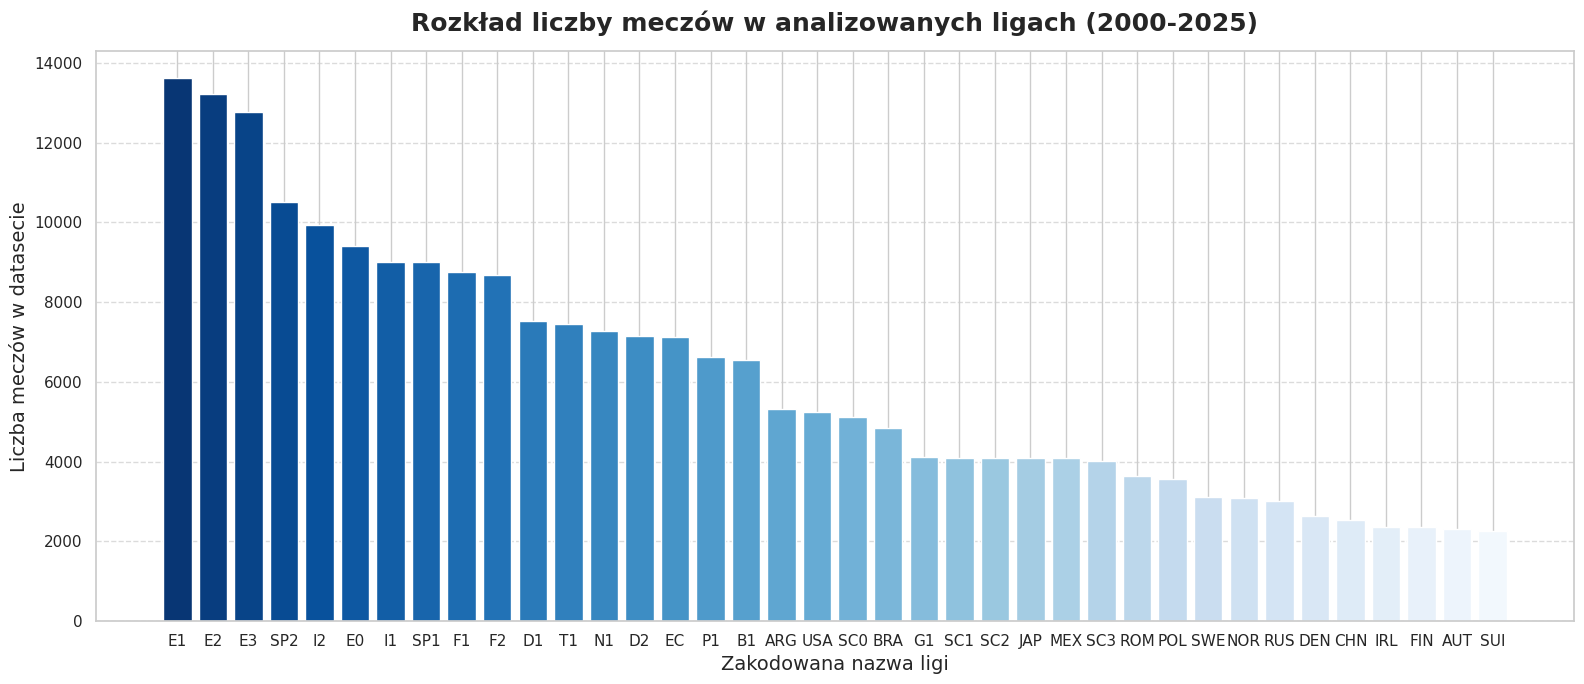

In [56]:
eksplorator.ilosc_meczow_w_ligach()

# rozkład zdobytych goli w zbiorze danych a rozkład poissona

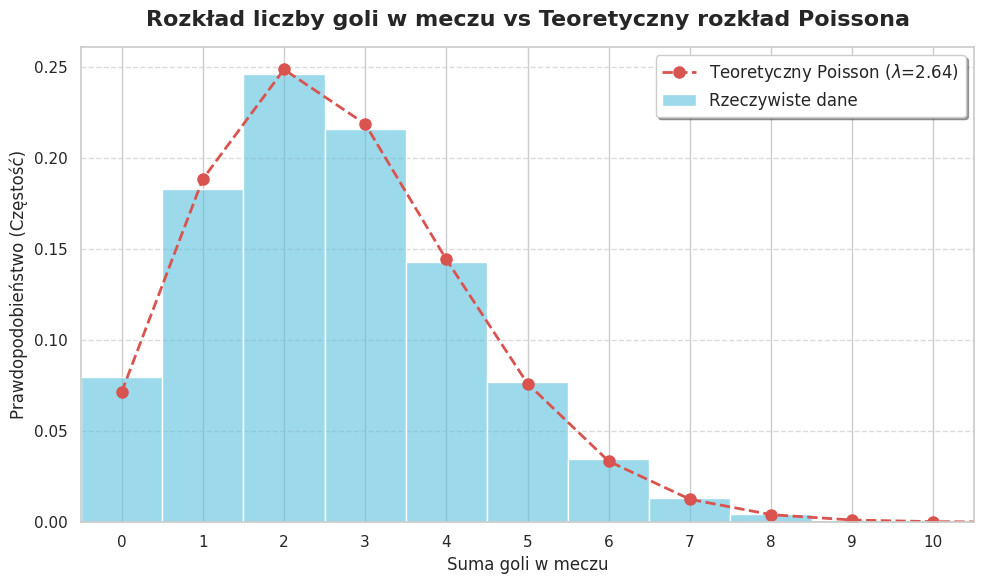

Średnia liczba goli w meczu to: 2.64


In [57]:
eksplorator.rysuj_rozklad_goli_poisson()

# Przewaga własnego boiska

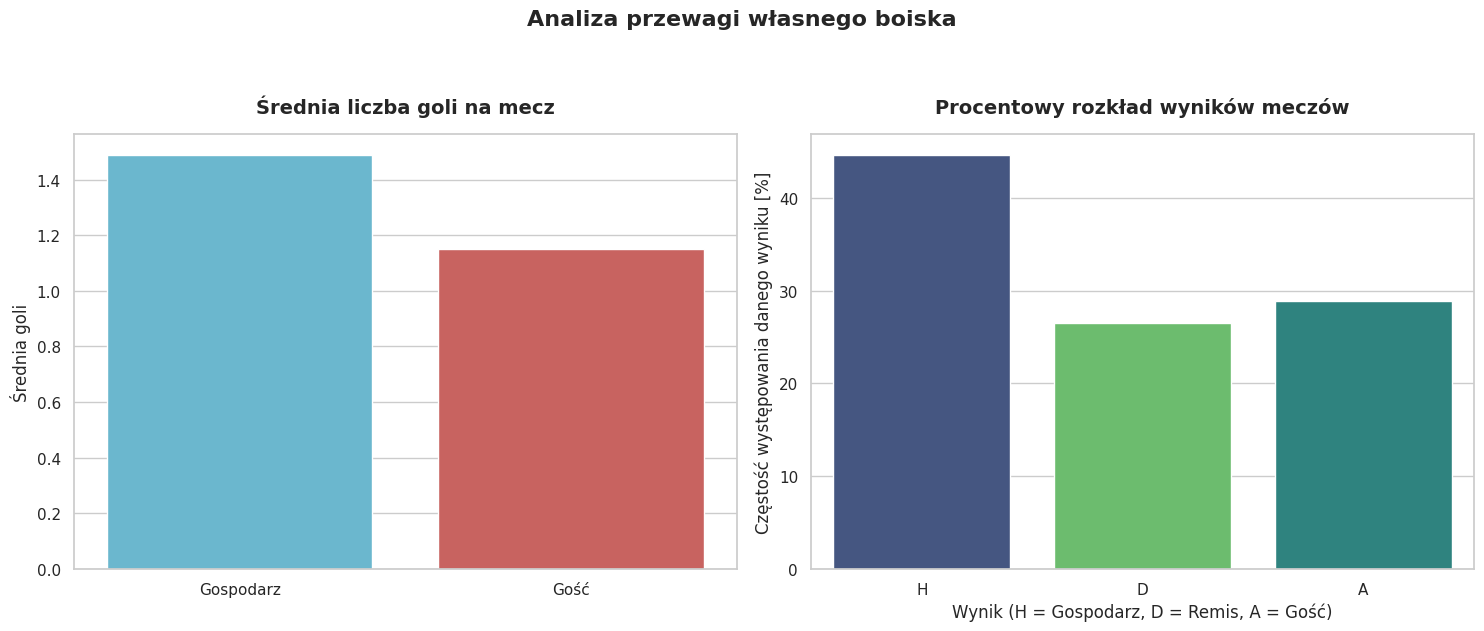

In [58]:
eksplorator.przewaga_wlasnego_boiska()

# Globalna zmiana lig

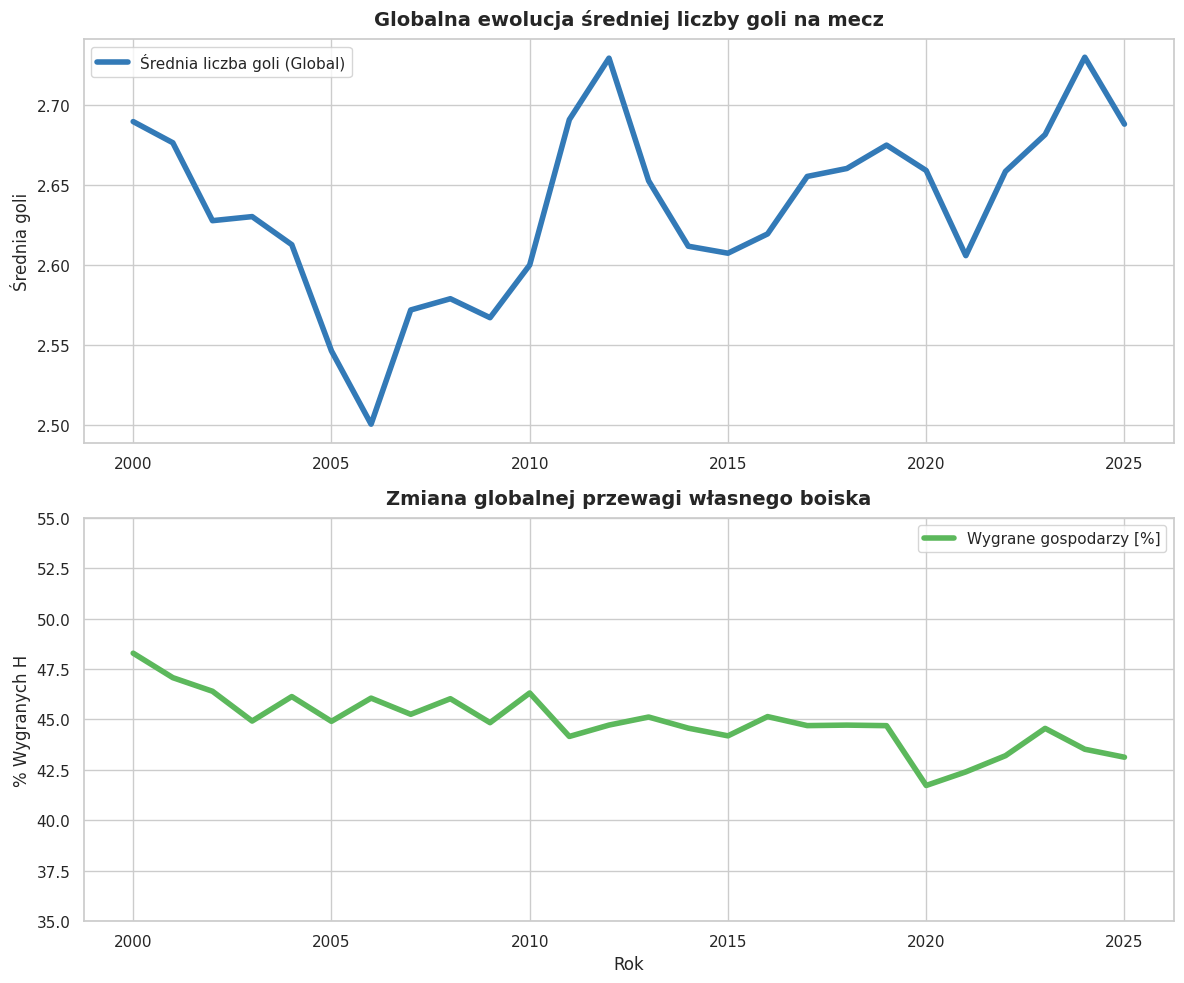

In [59]:
eksplorator.globalna_zmiana_lig()

# Potrzeba skalowania

In [60]:
eksplorator.potrzeba_skalowania()

,Średnia,Odchylenie std. (std),Zakres (Min - Max),Opis cechy
Nazwa cechy,,,,
HomeElo,"1533,12","153,28","1103,13 - 2107,48",Ranking Elo gospodarza
AwayElo,"1533,17","153,29","1103,13 - 2107,48",Ranking Elo gościa
Form5Home,"6,72","3,26","0,00 - 15,00",Średnia punktów gospodarza (5 meczów)
Form5Away,"6,93","3,27","0,00 - 15,00",Średnia punktów gościa (5 meczów)


In [61]:
preprocesing_class = DataPreprocessor(surowe_dane)
dane_wstepne = preprocesing_class.wykonaj_wstepny_preprocessing()
eksploracja_brakow = DataExplorer(dane_wstepne)

 ->  Nie ma żadnych duplikatów!
 -> Odrzucono drużyn: 31. Usunięto przez to 58 meczów.
 -> Usunięto 3 wierszy bez wektora wynikowego.
 -> Usunięto kolumny. Obecna liczba zmiennych w bazie: 27


# Braki danych przed usunięciem niszowych lig

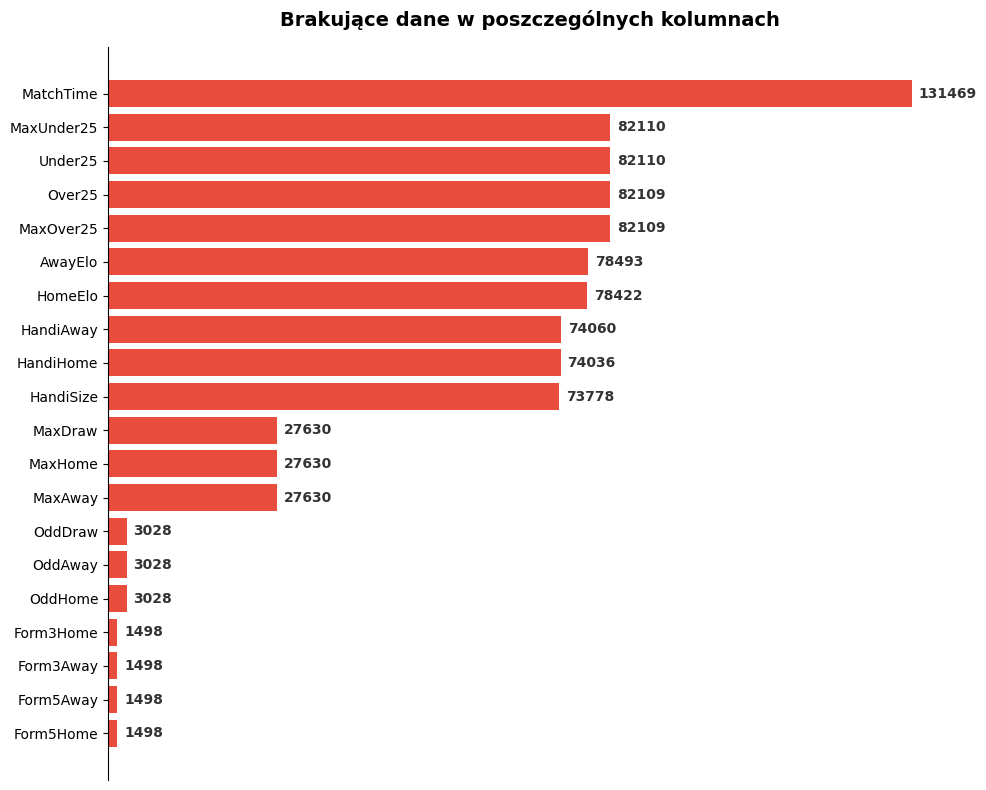

In [62]:
eksploracja_brakow.braki_danych_przed_usunieciem_lig()

# Raport jakości zbioru względem lig i kolumn z największą liczbą braków danych

In [63]:
eksploracja_brakow.pokaz_raport_brakow_ligowych()

,HomeElo,AwayElo,MatchTime,MaxHome,MaxDraw,MaxAway,Over25,Under25,MaxOver25,MaxUnder25,HandiSize,HandiHome,HandiAway,NAJGORSZA_KOLUMNA
Division,,,,,,,,,,,,,,
ARG,100%,100%,0%,0%,0%,0%,100%,100%,100%,100%,100%,100%,100%,100%
AUT,44%,44%,0%,0%,0%,0%,100%,100%,100%,100%,100%,100%,100%,100%
BRA,100%,100%,0%,0%,0%,0%,100%,100%,100%,100%,100%,100%,100%,100%
CHN,100%,100%,0%,0%,0%,0%,100%,100%,100%,100%,100%,100%,100%,100%
JAP,100%,100%,0%,0%,0%,0%,100%,100%,100%,100%,100%,100%,100%,100%
DEN,24%,24%,0%,0%,0%,0%,100%,100%,100%,100%,100%,100%,100%,100%
ROM,78%,78%,0%,0%,0%,0%,100%,100%,100%,100%,100%,100%,100%,100%
SWE,47%,47%,0%,0%,0%,0%,100%,100%,100%,100%,100%,100%,100%,100%
MEX,100%,100%,0%,0%,0%,0%,100%,100%,100%,100%,100%,100%,100%,100%


Widać, że w kolumnie Elo nadal występują braki danych. Interpolacja nie mogła tu wiele pomóc, ponieważ problem wynika z całkowitego braku informacji dla poszczególnych lig. Dodatkowo problematyczna okazuje się kolumna MatchTime – paradoksalnie, brakuje w niej danych głównie dla tych lig, które są kompletne pod względem innych cech. Dlatego zdecydowałem się usunąć tę kolumnę oraz odrzucić ligi zawierające ponad 50% braków w którejkolwiek z pozostałych zmiennych. Dzięki temu ewentualna imputacja danych nie wprowadzi do modelu niepotrzebnego szumu.

 ->  Usunięto 21 problematycznych lig: ['ARG', 'AUT', 'BRA', 'CHN', 'DEN', 'E2', 'E3', 'EC', 'FIN', 'IRL', 'JAP', 'MEX', 'NOR', 'ROM', 'RUS', 'SC1', 'SC2', 'SC3', 'SUI', 'SWE', 'USA']
 ->  Odpadło łącznie 96191 meczów (41.7% całości bazy).


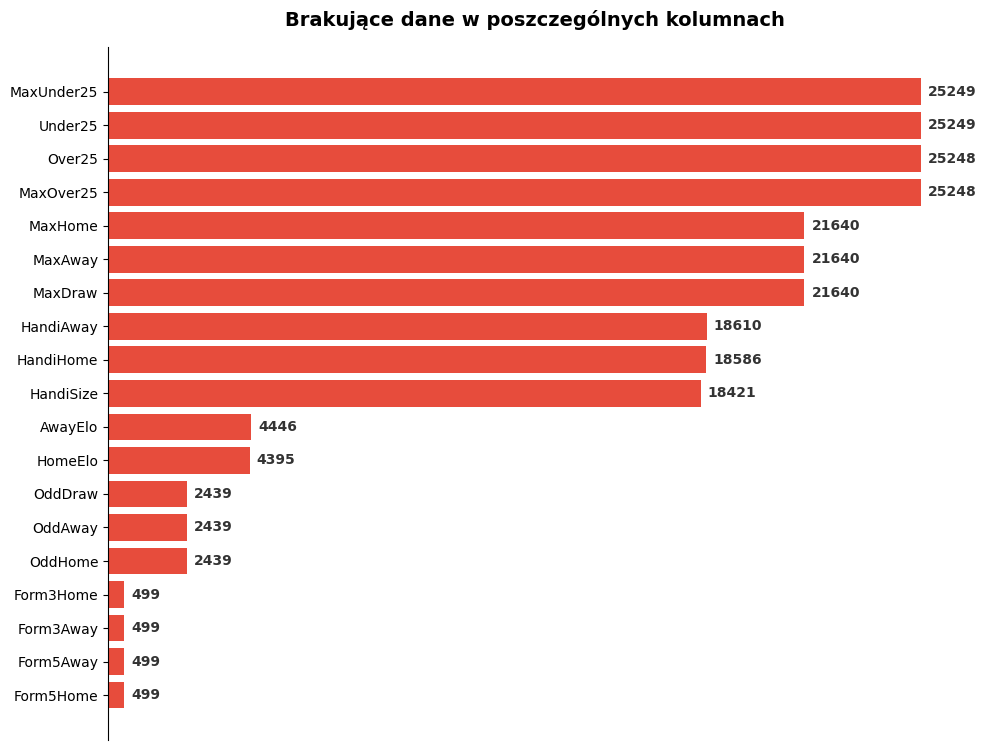

In [64]:
dane_bez_lig = preprocesing_class.usun_ligi_z_brakami(prog_brakow=0.50)
eksplorator_po = DataExplorer(dane_bez_lig)
eksplorator_po.braki_danych_przed_usunieciem_lig()

In [65]:
mecze_gotowe = preprocesing_class.wykonaj_dalszy_preprocessing(uzyj_kursow=False)

 -> Pozostałe braki w Elo: Gospodarze = 0, Goście = 0


# Preprocessor sklearn

In [66]:
X = mecze_gotowe.drop(columns=['wynik'])
y = mecze_gotowe['wynik']

X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.1, shuffle= False) # Dodałem shuffle = False bo chce zrobić lagged featres do szeregu czasowego

In [67]:
# Kolumny z Elo i Formą
stats_cols = [
    'HomeElo', 'AwayElo',
    'Form3Home', 'Form5Home', 'Form3Away', 'Form5Away'
]

# Cechy wyciągnięte z MatchDate i MatchTime 
date_features = ['DayOfWeek', 'Month', 'IsWeekend']

# Zmienne tekstowe do Encodingu
team_cols = ['HomeTeam', 'AwayTeam'] 
league_cols = ['Division']

X_train[team_cols + league_cols] = X_train[team_cols + league_cols].astype("category")
X_test[team_cols + league_cols] = X_test[team_cols + league_cols].astype("category")

wszystkie_potencjalne_odds = [
    'OddHome', 'OddDraw', 'OddAway', 'MaxHome', 'MaxDraw', 'MaxAway',
    'Over25', 'Under25', 'MaxOver25', 'MaxUnder25',
    'HandiSize', 'HandiHome', 'HandiAway'
]

wszystkie_potencjalne_derived = [
    "ImpliedProbHome", "ImpliedProbDraw", "ImpliedProbAway", "ImpliedProbTotal", 
    "BookmakerMargin", "OUMargin",
    "Odd1X", "OddX2", "Odd12",
    "EloDifference", "EloTotal", "EloAdvantage",
    "Form3Difference", "Form5Difference", "FormMomentumDiff",
    "MaxOddsValueHome", "MaxOddsValueAway", "MaxOddsValueDraw",
    "EloVsHandicap", "DrawLikelihood"
]

all_odds_cols = [col for col in wszystkie_potencjalne_odds if col in X_train.columns]
derived_cols = [col for col in wszystkie_potencjalne_derived if col in X_train.columns]



In [68]:
# Definicja Encodera dla nazw drużyn (ponieważ mamy wiele drużyn to kalsyczny One-Hot-Encoding spowdowałby 
# problem wielowymairowości )
hashing_step = ce.HashingEncoder(
    n_components=32,  # Kompresujemy setki nazw drużyn do 32 kolumn, dałem ilość na oko
)

In [69]:
et_imputer = IterativeImputer(
    ExtraTreesRegressor(n_estimators=30, max_depth=10,min_samples_leaf=4, n_jobs=4, random_state=42),
    max_iter=10,keep_empty_features=True, random_state=42
)

odds_pipeline = Pipeline(steps=[
    ('imputer', et_imputer),
    ('scaler', StandardScaler())
])

stats_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

date_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('scaler', StandardScaler())
])

team_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='constant', fill_value='brak_danych')),
    ('hash', ce.HashingEncoder(n_components=32))
])

league_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='constant', fill_value='brak_danych')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])


derived_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')), # Iterativ Imputer nie miałby tu sensu, bo są to zależności 
    ('scaler', StandardScaler()) # od innych kolumn z definicji
])


# Najpierw tworzymy listę podstawowych transformacji (tych, które są zawsze)
aktywne_transformatory = [
    ('stats', stats_pipeline, stats_cols),
    ('date', date_pipeline, date_features),
    ('derived', derived_pipeline, derived_cols),
    ('teams', team_pipeline, team_cols),         
    ('league', league_pipeline, league_cols),
]


if len(all_odds_cols) > 0:
    aktywne_transformatory.append(('odds', odds_pipeline, all_odds_cols))

preprocessor = ColumnTransformer(
    transformers=aktywne_transformatory,
    remainder='drop' # Ignoruje wszystko, co nie zostało jawnie określone
)

In [70]:
"""
Przygotowanie zbioru walidacyjnego w celu dobrania parametrów modeli uczenia masznowego, zrezygnowałem z klasycznej
kroswalidacji, ponieważ dobieranie najlepszych parametrów za pomocą optuny i trening będzie odbywać się na gpu, 
natomiast nie mogłem znaleźć odpowiedników wszystkich funkcji do preprocessingu a wszczególności pipeline na gpu,
a ponieważ nasze dane traktujemy jako szereg czasowy (ponieważ nie chcemy aby model uczył się na meczach z przyszłości
by nie miał dostępu, np. do aktualizacji formy z ostatnich 5 meczów z przyszłości), zajęłoby to o wiele więcej czasu
jeśli za każdym podziałem w k-fold kroswalidacji musielibyśmy robić od nowa fit_transform oraz transform i znacząco
wydłużyłoby czas działania optuny, w zamian az bardzo niewielki zysk predykcyjny
"""
X_train_tune, X_val_tune, y_train_tune, y_val_tune = train_test_split(
    X_train, y_train, test_size=0.2, shuffle=False
)
X_train_tune_prep = preprocessor.fit_transform(X_train_tune)
X_val_tune_prep = preprocessor.transform(X_val_tune)

# Modele Naiwne

In [71]:
class ModeleNaiwne:
    """
    Klasa przechowująca modele bazowe (naiwne), które służą jako 
    punkt odniesienia (baseline) dla zaawansowanych algorytmów ML.
    """
    
    def __init__(self):
        # Słownik do przechowywania wyników wszystkich modeli naiwnych
        self.wyniki = {}

    def model_losowy(self, y_test):
        """
        Model całkowicie losowy. 
        Zakłada równe prawdopodobieństwo (33.3%) 
        dla każdego z trzech wyników (0=Gospodarz, 1=Remis, 2=Gość).
        """
        y_test_int = np.asarray(y_test, dtype=int)
        n_samples = len(y_test_int)
        
        # Stałe prawdopodobieństwo 1/3 dla każdej z 3 klas
        y_proba = np.full((n_samples, 3), 1/3)
        np.random.seed(42)
        y_pred = np.random.choice([0, 1, 2], size=n_samples)
        
        # Obliczanie metryk
        acc = accuracy_score(y_test_int, y_pred)
        ll = log_loss(y_test_int, y_proba)
        brier = np.mean(np.sum((y_proba - np.eye(3)[y_test_int])**2, axis=1))
        
        # Zapisanie wyników do słownika
        self.wyniki['Losowy (33/33/33)'] = {'Accuracy': acc, 'LogLoss': ll, 'Brier': brier}
        
        return y_proba, y_pred

    def model_czesciowo_losowy(self, X_train, y_train, X_test, y_test):
        """
        Model częściowo losowy 
        Dla każdego meczu wystawia stały procent wyciągnięty z historycznych proporcji zbioru.
        """
        y_test_int = np.asarray(y_test, dtype=int)
        
        dummy = DummyClassifier(strategy='prior')
        dummy.fit(X_train, y_train)
        
        y_proba = dummy.predict_proba(X_test)
        y_pred = dummy.predict(X_test)
        
        acc = accuracy_score(y_test_int, y_pred)
        ll = log_loss(y_test_int, y_proba)
        brier = np.mean(np.sum((y_proba - np.eye(3)[y_test_int])**2, axis=1))
        
        self.wyniki['Częściowo Losowy (Prior)'] = {'Accuracy': acc, 'LogLoss': ll, 'Brier': brier}
        
        return y_proba, y_pred

    def model_zawsze_gospodarz(self, X_train, y_train, X_test, y_test):
        """
         Model naiwny: Zawsze Gospodarz (Most Frequent)
        Ślepo typuje wygraną u siebie (0) dla każdego spotkania, ponieważ statystycznie najczęściej to gospodarz
        wyrgywa dane spotkanie
        """
        y_test_int = np.asarray(y_test, dtype=int)
        
        dummy = DummyClassifier(strategy='most_frequent')
        dummy.fit(X_train, y_train)
        
        y_proba = dummy.predict_proba(X_test)
        y_pred = dummy.predict(X_test)
        
        acc = accuracy_score(y_test_int, y_pred)
        ll = log_loss(y_test_int, y_proba)
        brier = np.mean(np.sum((y_proba - np.eye(3)[y_test_int])**2, axis=1))
        
        self.wyniki['Zawsze Gospodarz'] = {'Accuracy': acc, 'LogLoss': ll, 'Brier': brier}
        
        return y_proba, y_pred

    def model_elo(self, X_train, y_train, X_test, y_test):
        """
        Model odniesienia, oparty tylko i wyłącznie na wartości Elo drużyn grających przeciwko sobie. Użyty w 
        celu ukazania jak ważna jest ta cecha w surowym zbiorze i jak dobre wyniki można uzyskać opierając model
        tylko na niej. W celu wyliczenia dokładnych prawdopodobieństw przynależności do danej klasy,
        użyty został model regresji logistycznej.
        """

        y_test_int = np.asarray(y_test, dtype=int)
        
        X_train_elo = X_train[['HomeElo', 'AwayElo']].copy()
        X_test_elo = X_test[['HomeElo', 'AwayElo']].copy()
    
        elo_model = SklearnLogisticRegression(
        solver='lbfgs', 
        random_state=42
        )

        elo_model.fit(X_train_elo, y_train)
        y_proba = elo_model.predict_proba(X_test_elo)
        y_pred = elo_model.predict(X_test_elo)

        acc = accuracy_score(y_test_int, y_pred)
        ll = log_loss(y_test_int, y_proba)
        brier = np.mean(np.sum((y_proba - np.eye(3)[y_test_int])**2, axis=1))
        
        self.wyniki['Model Elo'] = {'Accuracy': acc, 'LogLoss': ll, 'Brier': brier}
        
        return y_proba, y_pred
        
    def pokaz_podsumowanie(self):
        """
        Zwraca tabelę (DataFrame) ze wszystkimi przetestowanymi modelami i ich wynikami w określonych metrykach
        """
        
        df_wyniki = pd.DataFrame(self.wyniki).T
        return df_wyniki.sort_values(by='LogLoss', ascending=True)

In [72]:
# Inicjalizacja naszej klasy, tutaj nie ma żadnej optymalizacji hiperparametrów
baseline = ModeleNaiwne()

# Odpalamy algorytmy bazowe
wyniki_model_losowy = baseline.model_losowy(y_test)
wyniki_model_czesciowo_losowy = baseline.model_czesciowo_losowy(X_train, y_train, X_test, y_test)
wyniki_zawsze_gospodarz = baseline.model_zawsze_gospodarz(X_train, y_train, X_test, y_test)
wyniki_elo = baseline.model_elo(X_train, y_train, X_test, y_test)
# Generujemy tabelę wyników
tabela_baseline = baseline.pokaz_podsumowanie()
display(tabela_baseline)

,Accuracy,LogLoss,Brier
Model Elo,0.504802,1.002142,0.599049
Częściowo Losowy (Prior),0.441739,1.073029,0.648935
Losowy (33/33/33),0.336163,1.098612,0.666667
Zawsze Gospodarz,0.441739,20.121757,1.116521


# Modele Uczenia Masznowego

In [73]:
class ModeleML:
    def __init__(self):
        self.modele = {}
        self.studies = {}
        self.wyniki = {}

    def _ewaluuj_i_zapisz(self, nazwa_modelu, model, X_test, y_test):
        """Wspólna metoda ewaluacji dla  każdego modelu uczenia maszynowego (stworzona by zawęzić kod)"""
        y_test_int = np.asarray(y_test, dtype=int)
        y_proba = model.predict_proba(X_test)
        y_pred = model.predict(X_test)
        
        acc = accuracy_score(y_test_int, y_pred)
        ll = log_loss(y_test_int, y_proba)
        brier = np.mean(np.sum((y_proba - np.eye(3)[y_test_int])**2, axis=1))
        
        self.wyniki[nazwa_modelu] = {'Accuracy': acc, 'LogLoss': ll, 'Brier': brier}
        
        print("\n" + "="*50)
        print(f"WYNIKI: {nazwa_modelu.upper()} NA ZBIORZE TESTOWYM")
        print("="*50)
        print(f"Accuracy:    {acc:.4f}")
        print(f"Log Loss:    {ll:.4f}")
        print(f"Brier Score: {brier:.4f}")
        print("="*50)

    def _uruchom_pipeline_optuny(self, nazwa, objective_func, build_model_func, 
                                 X_train_final, y_train_full, X_test_final, y_test, n_trials):
        """
        GŁÓWNY SILNIK 
        Zajmuje się odpalanem Optuny, drukowaniem wyników, trenowaniem finalnego modelu i zapisem.
        """
        optuna.logging.set_verbosity(optuna.logging.WARNING) # wyłączenie komentarzy optuny
        study = optuna.create_study(
            direction="minimize", 
            study_name=nazwa, 
            sampler=optuna.samplers.TPESampler(seed=42)
            )
        study.optimize(objective_func, n_trials=n_trials)
        self.studies[nazwa] = study
        
        print("\n" + "="*50)
        print(f"NAJLEPSZE PARAMETRY: {nazwa.upper()}")
        print("="*50)
        for k, v in study.best_params.items():
            print(f" - {k}: {v}")
        print(f"Najlepszy walidacyjny Log Loss: {study.best_value:.4f}")
        
        print(f"\nTrenowanie finalnego modelu {nazwa} na pełnym zbiorze: ")
        
        # Budujemy model za pomocą zdefiniowanej funkcji
        model = build_model_func(study.best_params)
        model.fit(X_train_final, y_train_full)
        
        self.modele[nazwa] = model
        print("Trening zakończony")
        self._ewaluuj_i_zapisz(nazwa, model, X_test_final, y_test)
        return model
        
#########################################
    # METODY DLA KONKRETNYCH MODELI
#########################################

    # Pojedyńcze Drzewo Decyzyjne

    def trenuj_drzewo_decyzyjne(self, X_train_tune, y_train_tune, X_val_tune, y_val_tune, 
                                X_train_final, y_train_full, X_test_final, y_test, n_trials):
        print("Strojenie Drzewa Decyzyjnego w Optunie: ")
        
        def objective(trial):
            params = {
                "max_depth": trial.suggest_int("max_depth", 3, 20),
                "min_samples_split": trial.suggest_int("min_samples_split", 10, 200),
                "min_samples_leaf": trial.suggest_int("min_samples_leaf", 10, 100),
                "criterion": trial.suggest_categorical("criterion", ["gini", "entropy"]),
                "class_weight": trial.suggest_categorical("class_weight", [None, "balanced"])
            }
            model = DecisionTreeClassifier(**params, random_state=42)
            model.fit(X_train_tune, y_train_tune)
            return log_loss(y_val_tune, model.predict_proba(X_val_tune))

        def build_final_model(best_params):
            return DecisionTreeClassifier(**best_params, random_state=42)

        return self._uruchom_pipeline_optuny(
            "Decision Tree", objective, build_final_model, 
            X_train_final, y_train_full, X_test_final, y_test, n_trials
        )

    def trenuj_regresje_logistyczna_gpu(self, X_train_tune, y_train_tune, X_val_tune, y_val_tune, 
                                        X_train_final, y_train_full, X_test_final, y_test, n_trials=50):
        print("Strojenie Regresji Logistycznej w Optunie: ")
        
        # Wymuszone rzutowanie na GPU wewnątrz metody (podobno dla gpu najlepszym typem jest float32 i chciałem uniknąć
        # ewentualnych błędów )
        X_tt_gpu, y_tt_gpu = X_train_tune.astype('float32'), np.asarray(y_train_tune, dtype='int32')
        X_val_gpu, y_val_gpu = X_val_tune.astype('float32'), np.asarray(y_val_tune, dtype='int32')

        def objective(trial):
            penalty = trial.suggest_categorical("penalty", ["l1", "l2", "elasticnet"])
            params = {
                "penalty": penalty,
                "C": trial.suggest_float("C", 1e-6, 1e4, log=True),
                "l1_ratio": trial.suggest_float("l1_ratio", 0.01, 0.99) if penalty == "elasticnet" else None,
            }
            params = {k: v for k, v in params.items() if v is not None}
            
            model = LogisticRegression(
                solver="qn",           
                max_iter=2000,         
                output_type="numpy",   
                **params               
            )
            model.fit(X_tt_gpu, y_tt_gpu)
            return log_loss(y_val_gpu, model.predict_proba(X_val_gpu))

        def build_final_model(best_params):
            p = best_params.copy()
            if p.get("penalty") != "elasticnet" and "l1_ratio" in p:
                del p["l1_ratio"]

            return LogisticRegression(
                solver="qn",           
                max_iter=2000,         
                output_type="numpy",   
                **p                    
            )

        # Rzutujemy pełne zbiory na float32 przed wysłaniem do silnika
        return self._uruchom_pipeline_optuny(
            "Logistic Reg (GPU)", objective, build_final_model, 
            X_train_final.astype('float32'), np.asarray(y_train_full, dtype='int32'), 
            X_test_final.astype('float32'), np.asarray(y_test, dtype='int32'), n_trials
        )

    def trenuj_xgboost_gpu(self, X_train_tune, y_train_tune, X_val_tune, y_val_tune, 
                           X_train_final, y_train_full, X_test_final, y_test, n_trials=50):
        
        """3. XGBOOST (GPU)"""
        print("Strojenie XGBoost w Optunie: ")
        
        X_tt_gpu, y_tt_gpu = X_train_tune.astype('float32'), np.asarray(y_train_tune, dtype='int32')
        X_val_gpu, y_val_gpu = X_val_tune.astype('float32'), np.asarray(y_val_tune, dtype='int32')
        
        def objective(trial):
            params = {
                "n_estimators": trial.suggest_int("n_estimators", 200, 1500),
                "max_depth": trial.suggest_int("max_depth", 3, 8),
                "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.2, log=True),
                "subsample": trial.suggest_float("subsample", 0.6, 1.0),
                "colsample_bytree": trial.suggest_float("colsample_bytree", 0.6, 1.0),
                "gamma": trial.suggest_float("gamma", 0.0, 5.0),
                "min_child_weight": trial.suggest_int("min_child_weight", 1, 10),
                "reg_alpha": trial.suggest_float("reg_alpha", 1e-4, 10.0, log=True),
                "reg_lambda": trial.suggest_float("reg_lambda", 1.0, 10.0, log=True),
                "random_state": 42
            }

            model = XGBClassifier(
                device = "cuda",
                tree_method = "hist",
                eval_metric = "mlogloss", 
                early_stopping_rounds= 30,
                **params
            )
            
            # W Optunie używamy eval_set, by wcześnie zatrzymać słabe modele
            model.fit(
                X_tt_gpu, y_tt_gpu,
                eval_set=[(X_val_gpu, y_val_gpu)],
                verbose=False
            )
            
            trial.set_user_attr("best_iteration", model.best_iteration)
            return log_loss(y_val_gpu, model.predict_proba(X_val_gpu))

        def build_final_model(best_params):
            p = best_params.copy()
            
            # Wyciągamy idealną liczbę drzew z Optuny, żeby zapobiec Overfittingowi
            best_iter = self.studies["XGBoost"].best_trial.user_attrs.get("best_iteration")
            if best_iter is not None:
                p["n_estimators"] = best_iter
                
            p.update({
                "device": "cuda",
                "tree_method": "hist",
                "eval_metric": "mlogloss",
                "random_state": 42
            })
            return XGBClassifier(**p)
            
        return self._uruchom_pipeline_optuny(
            "XGBoost", objective, build_final_model, 
            X_train_final.astype('float32'), np.asarray(y_train_full, dtype='int32'), 
            X_test_final.astype('float32'), np.asarray(y_test, dtype='int32'), n_trials
        )

    def trenuj_random_forest_gpu(self, X_train_tune, y_train_tune, X_val_tune, y_val_tune, 
                                 X_train_final, y_train_full, X_test_final, y_test, n_trials=50):
        print("Strojenie Random Forest w Optunie: ")
        
        # float32 dla X oraz int32 dla y dla cuMl
        X_tt_gpu, y_tt_gpu = X_train_tune.astype('float32'), np.asarray(y_train_tune, dtype='int32')
        X_val_gpu = X_val_tune.astype('float32')

        def objective(trial):
            params = {
                "n_estimators": trial.suggest_int("n_estimators", 100, 500),
                "max_depth": trial.suggest_int("max_depth", 5, 18),
                "max_features": trial.suggest_float("max_features", 0.2, 0.8),
                "max_samples": trial.suggest_float("max_samples", 0.5, 0.9),
                "min_samples_split": trial.suggest_int("min_samples_split", 2, 20),
                "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 10),
                "n_bins": trial.suggest_int("n_bins", 64, 256),
                "split_criterion": trial.suggest_categorical("split_criterion", [0, 1]),
                "min_impurity_decrease": trial.suggest_float("min_impurity_decrease", 0.0, 0.01),
                "max_batch_size": 4096,
                "output_type": "numpy",
                "random_state": 42
            }
            
            model = RandomForestClassifier(**params)
            model.fit(X_tt_gpu, y_tt_gpu)
            return log_loss(np.asarray(y_val_tune, dtype='int32'), model.predict_proba(X_val_gpu))

        def build_final_model(best_params):
            p = best_params.copy()
            p["output_type"] = "numpy"
            p["random_state"] = 42
            return RandomForestClassifier(**p)

        return self._uruchom_pipeline_optuny(
            "Random Forest (GPU)", objective, build_final_model, 
            X_train_final.astype('float32'), np.asarray(y_train_full, dtype='int32'), 
            X_test_final.astype('float32'), np.asarray(y_test, dtype='int32'), n_trials
        )

    def pokaz_podsumowanie(self):
        if not self.wyniki: return "Brak wyników."
        return pd.DataFrame(self.wyniki).T.sort_values(by='LogLoss', ascending=True)

In [74]:
# Przygtotwanie danych
X_train_final_prep = preprocessor.fit_transform(X_train)
X_test_final_prep = preprocessor.transform(X_test)


# INICJALIZACJA KLASY MODELI ML

modele_ml = ModeleML()
LICZBA_PROB = 50 


# TRENING WSZYSTKICH MODELI ML

# 1.Drzewo Decyzyjne 
dt_model = modele_ml.trenuj_drzewo_decyzyjne(
    X_train_tune_prep, y_train_tune, X_val_tune_prep, y_val_tune, 
    X_train_final_prep, y_train, X_test_final_prep, y_test,
    n_trials=LICZBA_PROB
)

# 2. Regresja Logistyczna 
lr_model = modele_ml.trenuj_regresje_logistyczna_gpu(
    X_train_tune_prep, y_train_tune, X_val_tune_prep, y_val_tune, 
    X_train_final_prep, y_train, X_test_final_prep, y_test,
    n_trials=LICZBA_PROB
)

# 3. XGBoost 
xgb_model = modele_ml.trenuj_xgboost_gpu(
    X_train_tune_prep, y_train_tune, X_val_tune_prep, y_val_tune, 
    X_train_final_prep, y_train, X_test_final_prep, y_test,
    n_trials=LICZBA_PROB
)

# 4. Random Forest 
rf_model = modele_ml.trenuj_random_forest_gpu(
    X_train_tune_prep, y_train_tune, X_val_tune_prep, y_val_tune, 
    X_train_final_prep, y_train, X_test_final_prep, y_test,
    n_trials=LICZBA_PROB
)

# WYŚWIETLENIE TABELI WYNIKÓW

tabela_wynikow = modele_ml.pokaz_podsumowanie()
display(tabela_wynikow)

Strojenie Drzewa Decyzyjnego w Optunie: 

NAJLEPSZE PARAMETRY: DECISION TREE
 - max_depth: 4
 - min_samples_split: 108
 - min_samples_leaf: 62
 - criterion: gini
 - class_weight: None
Najlepszy walidacyjny Log Loss: 1.0189

Trenowanie finalnego modelu Decision Tree na pełnym zbiorze: 
Trening zakończony

WYNIKI: DECISION TREE NA ZBIORZE TESTOWYM
Accuracy:    0.5035
Log Loss:    1.0016
Brier Score: 0.5987
Strojenie Regresji Logistycznej w Optunie: 
[2026-09-08 15:57:23.242] [CUML] [warning] QWL-QN line search failed (code 3); stopping at the last valid step
[2026-09-08 15:57:23.371] [CUML] [warning] QWL-QN stopped, because the line search failed to advance (step delta = 0.000000)
[2026-09-08 15:57:24.179] [CUML] [warning] QWL-QN line search failed (code 3); stopping at the last valid step
[2026-09-08 15:57:24.349] [CUML] [warning] QWL-QN line search failed (code 3); stopping at the last valid step
[2026-09-08 15:57:24.800] [CUML] [warning] QWL-QN line search failed (code 3); stopping at

,Accuracy,LogLoss,Brier
XGBoost,0.504356,1.000322,0.597890
Random Forest (GPU),0.504505,1.000656,0.598135
Logistic Reg (GPU),0.504579,1.001563,0.598720
Decision Tree,0.503537,1.001576,0.598728


# Modele Statystyczne

In [75]:
class ModeleStatystyczne:
    """
    Klasa przeznaczona dla uogólnionych modeli liniowych (GLM; model Poissona i Regresja Logistyczna)
    i klasycznej statystyki.
    Skupia się na wnioskowaniu, interpretacji parametrów (P-Values)
    oraz ocenie błędu przewidywania liczby bramek i wyniku.
    """
    
    def __init__(self):
        self.model_poisson = None
        self.formula_poisson = None
        self.wyniki_bramek = {}
        self.wyniki_klasyfikacji = {}

    def trenuj_model_poissona(self, df_poisson_train, formula):
        """
        Trenuje model statystyczny poissona i wyświetla P-value dla naszych zmiennych. 
        """
        self.formula_poisson = formula
        
        print("TRENING MODELU REGRESJI POISSONA)")
        print(f"Zmienne użyte w modelu: {self.formula_poisson}\n")
        
        
        try:
            self.model_poisson = smf.poisson(formula=self.formula_poisson, data=df_poisson_train).fit(maxiter=100)
            print("WYNIKI (Kolumna P>|z| reprezentuje p-value dla odpowiedniej zmiennej):")
            print(self.model_poisson.summary().tables[1])
            
        except Exception as e:
            print(f"Błąd podczas trenowania modelu Poissona: {e}")
            print("Upewnij się, że w danych nie ma wartości NaN lub zmiennych idealnie współliniowych.")
            
        return self.model_poisson

    def ocena_poissona_bramki(self, df_poisson_test):
        """
        Ocenia zdolność modelu Poissona do przewidywania dokładnej liczby strzelonych goli. W tym celu posłużyłem
        się metrykami MAE, MSE i RMSE - pierwiastek z MSE
        """
        
        # Generujemy przewidywane średnie liczby goli (intensywności z rozkładu Poissona) dla każdej drużyny
        lambdy_test = self.model_poisson.predict(df_poisson_test)
        
        # Wyciągamy prawdziwą liczbę goli strzelonych w tych meczach
        true_goals_test = df_poisson_test["Goals"]

        # Kalkulacja metryk
        mae = mean_absolute_error(true_goals_test, lambdy_test)
        mse = mean_squared_error(true_goals_test, lambdy_test)
        rmse = np.sqrt(mse)

        # Zapisujemy w obiekcie
        self.wyniki_bramek = {"mae": mae, "mse": mse, "rmse": rmse}

        #  Ocena wyników predykcji strzelonych goli 
        print("OCENA JAKOŚCI MODELU POISSONA W PREDYKCJI STRZELONYCH GOLI:")
        print(f"Średni błąd bezwzględny (MAE): {mae:.3f} gola na drużynę")
        print(f"Błąd średniokwadratowy (MSE):  {mse:.3f}")
        print(f"Pierwiastek błędu (RMSE):       {rmse:.3f} gola na drużynę")
        
        return self.wyniki_bramek
        
    def _poisson_lambdy_na_1x2_dixon_coles(self, lambda_home, lambda_away, omega=0.0, max_goals=15):
        """
        Przelicza lambdy oznaczające oczekiwaną ilość strzelonych goli 
        na prawdopodobieństwa 1X2 z uwzględnieniem korekty 
        na niskie remisy - Dixon & Coles).
        """
        # Bazowa macierz niezależnego rozkładu Poissona, bez uwględniania skrajnych wyników, które zdarzają się za 
        # rzadko aby niosły jakąś istotną informację 
        prob_matrix = np.outer(
            poisson.pmf(range(max_goals + 1), lambda_home),
            poisson.pmf(range(max_goals + 1), lambda_away)
        )
        
        # Korekty parametrów wg. Dixona & Colesa
        if omega != 0.0:
            prob_matrix[0, 0] *= (1 - lambda_home * lambda_away * omega)
            prob_matrix[0, 1] *= (1 + lambda_home * omega)
            prob_matrix[1, 0] *= (1 + lambda_away * omega)
            prob_matrix[1, 1] *= (1 - omega)
            
            # Zabezpieczenie: przy ekstremalnych wartościach lambd i omega prawdopodobieństwo
            # teoretycznie mogłoby spaść poniżej 0. 
            prob_matrix = np.clip(prob_matrix, a_min=0, a_max=None)
        
        # Sumowanie przekątnych i trójkątów
        home_win = np.sum(np.tril(prob_matrix, -1))
        draw = np.sum(np.diag(prob_matrix))         
        away_win = np.sum(np.triu(prob_matrix, 1))  
        
        # Ponowna normalizacja. Ponieważ sztucznie zmieniliśmy wagi kilku wyników,
        # musimy upewnić się, że całkowita suma (1, X, 2) wynosi dokładnie 1.0
        total_prob = home_win + draw + away_win
        
        return [home_win / total_prob, draw / total_prob, away_win / total_prob]

    def ocena_poissona_klasyfikacja(self, df_poisson_test, omega=0.0):
        """
        Ocenia zdolność modelu Poissona do przewidywania wyników meczy
        Zwraca macierz prawdopodobieństw.
        """

        # Dzielimy zbiór w celu zachowania chronologii
        df_home = df_poisson_test[df_poisson_test['Home'] == 1].reset_index(drop=True)
        df_away = df_poisson_test[df_poisson_test['Home'] == 0].reset_index(drop=True)

        # Wyliczamy Lambdy
        lambdy_home = self.model_poisson.predict(df_home)
        lambdy_away = self.model_poisson.predict(df_away)

        # Generowanie macierzy prawdopodobieństw
        y_proba = []
        for lh, la in zip(lambdy_home, lambdy_away):
            y_proba.append(self._poisson_lambdy_na_1x2_dixon_coles(lh, la, omega=omega))
            
        y_proba = np.array(y_proba)
        
        # Normalizacja, by wiersze sumowały się do równego 1
        y_proba = y_proba / np.sum(y_proba, axis=1, keepdims=True)

        # Generujemy prawdziwy wektor wyników na podstawie prawdziwych goli
        gole_home = df_home['Goals'].values
        gole_away = df_away['Goals'].values
        
        warunki = [
            (gole_home > gole_away),
            (gole_home == gole_away),
            (gole_home < gole_away)
        ]
        y_test_true = np.select(warunki, [0, 1, 2])
        y_pred = np.argmax(y_proba, axis=1)

        # Metryki klasyfikacji
        acc = accuracy_score(y_test_true, y_pred)
        ll = log_loss(y_test_true, y_proba)
        
        y_true_one_hot = np.eye(3)[y_test_true]
        brier = np.mean(np.sum((y_proba - y_true_one_hot)**2, axis=1))

        self.wyniki_klasyfikacji['Poisson'] = {'Accuracy': acc, 'LogLoss': ll, 'Brier': brier}

        print("\n" + "="*50)
        print("WYNIKI KLASYFIKACJI MODELU POISSONA DLA PRZEWIDYWANIA WYNIKÓW:")
        print(f"   (Zastosowana korekta remisów Omega = {omega:.4f})")
        print("="*50)
        print(f"Accuracy:    {acc:.4f} ({(acc*100):.1f}%)")
        print(f"Log Loss:    {ll:.4f}")
        print(f"Brier Score: {brier:.4f}")
        print("="*50)

        return y_proba

    def optymalizuj_parametr_omega(self, df_poisson_train):
        """
        Znajduje optymalną wartość parametru omega (korekty remisów Dixon-Coles).
        Używam do tego funkcji scipy.minimize_scalar z funkcją negative log likelihood
        """
            
        print("\n" + "="*50)
        print("OPTYMALIZACJA PARAMETRU OMEGA (DIXON-COLES)")
        print("="*50)

        # Przecinamy zbiór na pół
        df_home = df_poisson_train[df_poisson_train['Home'] == 1].reset_index(drop=True)
        df_away = df_poisson_train[df_poisson_train['Home'] == 0].reset_index(drop=True)
        
        # Wyciągamy historyczne Lambdy i rzeczywiste gole
        lh_series = self.model_poisson.predict(df_home)
        la_series = self.model_poisson.predict(df_away)
        hg_series = df_home['Goals']
        ag_series = df_away['Goals']

        # Tableka faktycznej i przewidzianej liczby goli
        df_optymalizacja = pd.DataFrame({
            'lh': lh_series,
            'la': la_series,
            'hg': hg_series,
            'ag': ag_series
        })

        # Odrzucamy wszystkie wiersze z NaN jednym poleceniem!
        ile_przed = len(df_optymalizacja)
        df_optymalizacja = df_optymalizacja.dropna()
        ile_po = len(df_optymalizacja)
        
        if ile_przed > ile_po:
            print(f"[*] Odrzucono {ile_przed - ile_po} niepełnych meczów z powodu wartości NaN.")

        # Wyciągamy czyste wektory
        lh = df_optymalizacja['lh'].values
        la = df_optymalizacja['la'].values
        hg = df_optymalizacja['hg'].values
        ag = df_optymalizacja['ag'].values
            
        # Funkcja ujemnej log wiarygodności 
        def negative_log_likelihood(omega):
            prob_base = poisson.pmf(hg, lh) * poisson.pmf(ag, la)
            tau = np.ones(len(hg))
            
            idx_00 = (hg == 0) & (ag == 0)
            idx_01 = (hg == 0) & (ag == 1)
            idx_10 = (hg == 1) & (ag == 0)
            idx_11 = (hg == 1) & (ag == 1)
            
            tau[idx_00] = 1 - lh[idx_00] * la[idx_00] * omega
            tau[idx_01] = 1 + lh[idx_01] * omega
            tau[idx_10] = 1 + la[idx_10] * omega
            tau[idx_11] = 1 - omega
            
            prob_adj = np.clip(prob_base * tau, 1e-10, 1.0)
            return -np.sum(np.log(prob_adj))

        
        # OPTYMALIZACJA 
        print("Optymalizacja parametru omega: ")
        
        wynik_optymalizacji = minimize_scalar(
            negative_log_likelihood, 
            bounds=(-0.2, 0.2), 
            method='bounded'
        )
        
        # Wyciągamy wyniki 
        najlepsze_omega = wynik_optymalizacji.x
        najmniejszy_blad = wynik_optymalizacji.fun
        
        if wynik_optymalizacji.success:
            print(f"Znalezione optymalne ω (rho): {najlepsze_omega:.6f}")
        else:
            print("Uwaga: Optymalizacja nie zbiegła się poprawnie.")
        
        return najlepsze_omega


    def trenuj_regresje_logistyczna(self, df_train_szerokie, formula):
        """
        Trenuje klasyczny model Regresji Logistycznej w wersji statystycznej      
        """
        
        print("TRENING MODELU: REGRESJA LOGISTYCZNA")

        
        # Przecinamy zbiór na pół
        df_home = df_train_szerokie[df_train_szerokie['Home'] == 1].reset_index(drop=True)
        df_away = df_train_szerokie[df_train_szerokie['Home'] == 0].reset_index(drop=True)
        
        df_logit = df_home.copy()
        
        # Tworzymy wektor wynikowy:
        warunki = [
            (df_home['Goals'] < df_away['Goals']),
            (df_home['Goals'] == df_away['Goals']),
            (df_home['Goals'] > df_away['Goals'])
        ]
        df_logit['Result'] = np.select(warunki, [0, 1, 2])
        
        # Feature Engineering
        df_logit['Form3Diff'] = df_logit['TeamForm3'] - df_logit['OpponentForm3']
        df_logit['Form5Diff'] = df_logit['TeamForm5'] - df_logit['OpponentForm5']
        df_logit['EloDiff'] = df_logit['TeamElo'] - df_logit['OpponentElo']
        
        try:
            # Trenujemy model Regresji Logistycznej
            self.model_logit = smf.mnlogit(formula=formula, data=df_logit).fit(disp=False)
            print("GOTOWE WYNIKI z P-VALUES:")
            print("-" * 50)
            print(self.model_logit.summary())
            
        except Exception as e:
            print(f"Błąd podczas trenowania Regresji Logistycznej: {e}")
            
        return self.model_logit

    def ocena_logit_klasyfikacja(self, df_test_szerokie):
        """
        Ocena jakości Regresji Logistycznej na zbiorze testowym.
        """
        # Przygotowanie danych testowych z ramki stworzonej na potrzeby modelu poissona
        df_home = df_test_szerokie[df_test_szerokie['Home'] == 1].reset_index(drop=True)
        df_away = df_test_szerokie[df_test_szerokie['Home'] == 0].reset_index(drop=True)
        
        df_logit_test = df_home.copy()
        df_logit_test['Form3Diff'] = df_logit_test['TeamForm3'] - df_logit_test['OpponentForm3']
        df_logit_test['Form5Diff'] = df_logit_test['TeamForm5'] - df_logit_test['OpponentForm5']
        df_logit_test['EloDiff'] = df_logit_test['TeamElo'] - df_logit_test['OpponentElo']
        
        # Tworzymy wektor wynikowy
        warunki = [
            (df_home['Goals'] > df_away['Goals']),   
            (df_home['Goals'] == df_away['Goals']),  
            (df_home['Goals'] < df_away['Goals'])    
        ]
        y_test_true = np.select(warunki, [0, 1, 2])
        
        # Predykcja 
        y_proba = self.model_logit.predict(df_logit_test).values
        
        # Zamieniamy kolejność kolumn, żeby pasowała do naszego standardu (Wygrana, Remis, Porażka)
        # MNLogit domyślnie zwraca prawdopodobieństwa dla klas: [Porażka(0), Remis(1), Wygrana(2)]
        y_proba = y_proba[:, [2, 1, 0]]
        
        y_pred = np.argmax(y_proba, axis=1)
        acc = accuracy_score(y_test_true, y_pred)
        ll = log_loss(y_test_true, y_proba)

        # Obliczanie Brier Score dla 3 klas
        y_true_one_hot = np.eye(3)[y_test_true]
        brier = np.mean(np.sum((y_proba - y_true_one_hot)**2, axis=1))

        # Zapis do słownika wyników (sprawdź czy ta zmienna istnieje w Twojej klasie)
        self.wyniki_klasyfikacji['Regresja Logistyczna (MNLogit)'] = {
            'Accuracy': acc,
            'LogLoss': ll,
            'Brier': brier
        }

        print("\n" + "="*50)
        print(" WYNIKI KLASYFIKACJI REGRESJI LOGISTYCZNEJ:")
        print("="*50)
        print(f"Accuracy:    {acc:.4f} ({(acc*100):.1f}%)")
        print(f"Log Loss:    {ll:.4f}")
        print(f"Brier Score: {brier:.4f}") # Dodany wydruk Brier Score
        print("="*50)
        
        return y_proba

# Model Poissona

In [76]:
# Podział na train i test dla modelu poissona
df_train = surowe_dane.loc[X_train.index]
df_test = surowe_dane.loc[X_test.index]


print("Przygotowanie zbioru treningowego dla modelu poissona")
prep_train = DataPreprocessor(df_train) 

# Odpalamy cały preprocesor 
prep_train.wykonaj_wstepny_preprocessing(min_mecze_druzyny=10)
prep_train.usun_ligi_z_brakami(prog_brakow=0.50)  
prep_train.wykonaj_dalszy_preprocessing(uzyj_kursow=False)

# Wyciągamy dane trenigowe dla modeli statystycznych
df_poisson_train = prep_train.pobierz_dane_poisson()

print("Przygotowanie zbioru testowego dla modelu poissona")
prep_test = DataPreprocessor(df_test) 

prep_test.wykonaj_wstepny_preprocessing(min_mecze_druzyny=0)
prep_test.usun_ligi_z_brakami(prog_brakow=0.50)  
prep_test.wykonaj_dalszy_preprocessing(uzyj_kursow=False)

# Wyciągamy czyste dane testowe dla poissona
df_poisson_test = prep_test.pobierz_dane_poisson()

Przygotowanie zbioru treningowego dla modelu poissona
 ->  Nie ma żadnych duplikatów!
 -> Odrzucono drużyn: 2. Usunięto przez to 4 meczów.
 -> Wszystkie mecze posiadają wektor wynikowy.
 -> Usunięto kolumny. Obecna liczba zmiennych w bazie: 27
 ->  Usunięto 0 problematycznych lig: []
 ->  Odpadło łącznie 0 meczów (0.0% całości bazy).
 -> Pozostałe braki w Elo: Gospodarze = 0, Goście = 0
Przygotowanie zbioru testowego dla modelu poissona
 ->  Nie ma żadnych duplikatów!
 -> Wszystkie drużyny spełniają kryterium minimalnej liczby spotkań.
 -> Wszystkie mecze posiadają wektor wynikowy.
 -> Usunięto kolumny. Obecna liczba zmiennych w bazie: 27
 ->  Usunięto 0 problematycznych lig: []
 ->  Odpadło łącznie 0 meczów (0.0% całości bazy).
 -> Pozostałe braki w Elo: Gospodarze = 0, Goście = 0


In [77]:
modele_stat = ModeleStatystyczne()

# MODEL 1: POISSON 


print("MODEL 1: MODEL POISSONA Z KOREKTĄ REMISÓW (DIXON-COLES)")


# Formuła badawcza 
formula_poisson = "Goals ~ Home + EloDiff + EloTotal + Form5Diff + C(Division)"

# Trening modelu poissona
poiss_model= modele_stat.trenuj_model_poissona(df_poisson_train, formula=formula_poisson)

# Szukanie parametru remisów (poprawki Dixona-Colesa)
znaleziona_omega = modele_stat.optymalizuj_parametr_omega(df_poisson_train)

# Zbieranie prawdopodobieństw 1X2 na zbiorze testowym i ocena modelu 
probs_poisson = modele_stat.ocena_poissona_klasyfikacja(df_poisson_test, omega=znaleziona_omega)

MODEL 1: MODEL POISSONA Z KOREKTĄ REMISÓW (DIXON-COLES)
TRENING MODELU REGRESJI POISSONA)
Zmienne użyte w modelu: Goals ~ Home + EloDiff + EloTotal + Form5Diff + C(Division)

Optimization terminated successfully.
         Current function value: 1.430958
         Iterations 9
WYNIKI (Kolumna P>|z| reprezentuje p-value dla odpowiedniej zmiennej):
                         coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------
Intercept             -0.1003      0.039     -2.585      0.010      -0.176      -0.024
C(Division)[T.D1]     -0.0111      0.012     -0.920      0.357      -0.035       0.013
C(Division)[T.D2]     -0.0142      0.011     -1.313      0.189      -0.035       0.007
C(Division)[T.E0]     -0.1153      0.012     -9.358      0.000      -0.140      -0.091
C(Division)[T.E1]     -0.0879      0.010     -9.146      0.000      -0.107      -0.069
C(Division)[T.F1]     -0.1683      0.012   

# Model Regresji Logistycznej w wersji statystycznej

In [78]:
# MODEL 2: REGRESJA LOGISTYCZNA 

# Formuła dla rynku 1X2. Nie używam tu 'Home', ponieważ model jest 
# uczony wyłącznie z perspektywy Gospodarza. 
formula_logit = "Result ~ Form3Diff + Form5Diff + EloDiff+ C(Division)"

# Trening modelu statystycznego Regresji Logistycznej
logit_model = modele_stat.trenuj_regresje_logistyczna(df_poisson_train, formula=formula_logit)

# Zbieranie prawdopodobieństw na zbiorze testowym
probs_logit = modele_stat.ocena_logit_klasyfikacja(df_poisson_test)

TRENING MODELU: REGRESJA LOGISTYCZNA
GOTOWE WYNIKI z P-VALUES:
--------------------------------------------------
                          MNLogit Regression Results                          
Dep. Variable:                 Result   No. Observations:               120371
Model:                        MNLogit   Df Residuals:                   120331
Method:                           MLE   Df Model:                           38
Date:                Tue, 08 Sep 2026   Pseudo R-squ.:                 0.05307
Time:                        16:00:06   Log-Likelihood:            -1.2175e+05
converged:                       True   LL-Null:                   -1.2857e+05
Covariance Type:            nonrobust   LLR p-value:                     0.000
          Result=1       coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------
Intercept             -0.0255      0.037     -0.697      0.486      -0.097      

# Analiza Wyników

In [79]:
class AnalizaWynikow:
    """
    Klasa do oceny porównawczej różnych modeli predykcyjnych. Użyłem jedynie modeli nienaiwnych, by wykresy były
    bardziej przejrzyste. Służy do generowania tabel porównawczych, analizy istotności cech oraz testów czasowych.
    """
    
    def __init__(self, test_df, y_test):
        
        self.test_df = test_df.reset_index(drop=True)
        self.y_test = np.asarray(y_test, dtype=int)
        
    def analiza_predykcji_ligi(self, modele_slownik):
        """
        Porównuje jakość wielu modeli z podziałem na ligi.
        """
        
        df_analiza = self.test_df[['Division']].copy()
        wyniki = []
        
        for liga in df_analiza['Division'].unique():
            maska = (df_analiza['Division'] == liga).values
            y_true_liga = self.y_test[maska]
            
            for nazwa_modelu, y_proba in modele_slownik.items():
                y_proba_liga = y_proba[maska]
                y_pred_liga = np.argmax(y_proba_liga, axis=1)
                    
                acc = accuracy_score(y_true_liga, y_pred_liga)
                ll = log_loss(y_true_liga, y_proba_liga, labels=[0, 1, 2])
                    
                wyniki.append({
                    'Liga': liga, 
                    'Mecze': len(y_true_liga), 
                    'Model': nazwa_modelu,
                    'Accuracy': round(acc, 4), 
                    'Log Loss': round(ll, 4)
                })
                    
        df_wyniki = pd.DataFrame(wyniki).sort_values(by=['Liga', 'Log Loss'])
        

        # TABELA Z LICZBĄ MECZÓW 
        df_mecze = df_wyniki[['Liga', 'Mecze']].drop_duplicates()
        
        # Ustawiamy 'Liga' jako indeks i robimy transpozycję 
        df_pozioma = df_mecze.set_index('Liga').T
        df_pozioma.columns.name = None 
        
        print("\n--- LICZBA MECZÓW W POSZCZEGÓLNYCH LIGACH (Zbiór testowy) ---")
        display(df_pozioma)
        print("\n" + "="*60 + "\n")
        
        print("ZBIORCZA JAKOŚĆ PREDYKCJ Z PODZIAŁEM NA LIGI: ")
        print(df_wyniki.to_string(index=False))

        pivot_df = df_wyniki.pivot(index='Liga', columns='Model', values='Log Loss')
        
        # RYSOWANIE WYKRESU 
        plt.figure(figsize=(12, 8)) 
        
        sns.heatmap(
            pivot_df, 
            annot=True,          
            fmt=".4f",           
            cmap="YlOrRd",      
            linewidths=.5,       
            cbar_kws={'label': 'Log Loss (Mniej = Lepiej)'}
        )
        
        plt.title("Porównanie błędu Log Loss modeli w poszczególnych ligach", fontsize=16, pad=15)
        plt.ylabel("Liga (Division)", fontsize=12)
        plt.xlabel("Model ML", fontsize=12)
        
        # Obracamy nazwy modeli na osi X, żeby na siebie nie nachodziły
        plt.xticks(rotation=45, ha='right')
        
        plt.tight_layout()
        plt.savefig('porownanie_lig_logloss.png', dpi=300)
        plt.show()
        
        return df_wyniki

    def analiza_predykcji_czasowa(self, modele_slownik, kolumna_data='MatchDate'):
        """
        Analizuje błąd predykcyjny modeli w ujęciu czasowym (rok po roku) 
        i generuje wykres trendu.
        """
        df_analiza = self.test_df.copy()
            
        df_analiza['Rok'] = pd.to_datetime(df_analiza[kolumna_data], format='mixed', dayfirst=True).dt.year
        
        wyniki = []
        dostepne_lata = sorted(df_analiza['Rok'].dropna().unique())
        
        for rok in dostepne_lata:
            maska = (df_analiza['Rok'] == rok).values
            if maska.sum() > 10:
                y_true_rok = self.y_test[maska]
                
                for nazwa_modelu, y_proba in modele_slownik.items():
                    y_proba_rok = y_proba[maska]
                    y_pred_rok = np.argmax(y_proba_rok, axis=1)
                    
                    acc = accuracy_score(y_true_rok, y_pred_rok)
                    ll = log_loss(y_true_rok, y_proba_rok, labels=[0, 1, 2])
                    
                    wyniki.append({
                        'Rok': int(rok), 
                        'Mecze': maska.sum(), 
                        'Model': nazwa_modelu,
                        'Accuracy': round(acc, 4), 
                        'Log Loss': round(ll, 4)
                    })
                    
        df_wyniki = pd.DataFrame(wyniki).sort_values(by=['Rok', 'Log Loss'])
        
        print("ZBIORCZA JAKOŚĆ PREDYKCJ ROK PO ROKU ")
        print(df_wyniki.to_string(index=False))
        
        # RYSOWANIE WYKRESU 
        sns.set_theme(style="whitegrid")
        plt.figure(figsize=(10, 6))
        sns.lineplot(
            data=df_wyniki, x='Rok', y='Log Loss', hue='Model', 
            marker='s', linewidth=3, markersize=10, palette="Set2" 
        )
        
        plt.title('Błąd modeli w czasie (Log Loss)', fontsize=16, fontweight='bold', pad=15)
        plt.ylabel('Log Loss', fontsize=12)
        plt.xlabel('Rok', fontsize=12)
        plt.xticks(dostepne_lata)
        
        plt.legend(title='Modele', bbox_to_anchor=(1.05, 1), loc='upper left', borderaxespad=0.)
        
        plt.tight_layout()
        plt.show()
        
        sns.reset_orig()
        
        return df_wyniki
        
    def analiza_wplywu_cech_zbiorcza(self, slownik_wytrenowanych_modeli, X_test_prep, prawdziwe_nazwy_kolumn, top_n):
        """
        Sprawdza ważność cech metodą Permutation dla różnych modeli 
        i generuje zbiorczą siatkę wykresów słupkowych z odchyleniami standardowymi.
        """
        
        print(f"\n Rozpoczynam Permutation Feature Importance dla {len(slownik_wytrenowanych_modeli)} modeli.")
        
        slownik_tlumaczen = {
            'derived_EloDifference': 'Różnica Elo',
            'EloDifference': 'Różnica Elo',
            'derived_EloAdvantage': 'Przewaga Elo',
            'EloAdvantage': 'Przewaga Elo',
            'Form3Away': 'Forma gości (3 mecze)',
            'Form5Difference': 'Różnica formy (5 meczów)',
            'Division_I2': 'Serie B (Włochy)',
            'Division_SP2': 'Segunda División (Hiszpania)',
            'stats_HomeElo': 'Elo Gospodarza',
            'HomeElo': 'Elo Gospodarza',
            'stats_AwayElo': 'Elo Gościa',
            'AwayElo': 'Elo Gościa',
            
            # Twoje starsze tłumaczenia:
            'EloDiff': 'Różnica Elo',
            'Form5Home': 'Forma Gosp. (5 meczów)',
            'Form5Away': 'Forma Gościa (5 meczów)',
            'league_Division_E0': 'Liga Angielska (E0)',
        }
        
        czyste_nazwy = []
        for nazwa in prawdziwe_nazwy_kolumn:
            czysta = nazwa.split('__')[-1] 
            czysta = slownik_tlumaczen.get(czysta, czysta)
            czyste_nazwy.append(czysta)

        liczba_modeli = len(slownik_wytrenowanych_modeli)
        kolumny = 2
        wiersze = math.ceil(liczba_modeli / kolumny)
        
        fig, axes = plt.subplots(wiersze, kolumny, figsize=(18, 7 * wiersze))
        axes = axes.flatten()
        
        slownik_wynikow = {}
        
        for idx, (nazwa_modelu, model) in enumerate(slownik_wytrenowanych_modeli.items()):
            print(f" -> Przetwarzam model: {nazwa_modelu}")
            
            wyniki = permutation_importance(
                model, X_test_prep, self.y_test, 
                scoring='neg_log_loss',  
                n_repeats=10,
                random_state=42,
            )
            
            df_imp = pd.DataFrame({
                'Cecha': czyste_nazwy, 
                'Wzrost Log Loss': wyniki.importances_mean,
                'Odchylenie std': wyniki.importances_std
            }).sort_values(by='Wzrost Log Loss', ascending=False)
            
            df_imp = df_imp[df_imp['Wzrost Log Loss'] > 0.0001]
            slownik_wynikow[nazwa_modelu] = df_imp
            
            df_plot = df_imp.head(top_n).copy()
            df_plot = df_plot.sort_values(by='Wzrost Log Loss', ascending=True)
            
            # Rysujemy słupki dla wybranych cech
            sns.barplot(
                x='Wzrost Log Loss', 
                y='Cecha', 
                data=df_plot, 
                palette='mako',
                hue='Cecha',
                legend=False,
                ax=axes[idx]
            )
            
            # Ręcznie nakładamy czarne "wąsy błędów" 
            axes[idx].errorbar(
                x=df_plot['Wzrost Log Loss'],
                y=range(len(df_plot)), 
                xerr=df_plot['Odchylenie std'],
                fmt='none', 
                c='black',
                capsize=5,
                elinewidth=1.5
            )
            
            axes[idx].set_title(f"{nazwa_modelu} - Najważniejsze cechy", fontsize=18, fontweight='bold', pad=15)
            axes[idx].set_xlabel("Średni wzrost błędu Log Loss", fontsize=14, fontweight='bold')
            axes[idx].set_ylabel("") 
            
            axes[idx].tick_params(axis='y', labelsize=14)
            axes[idx].tick_params(axis='x', labelsize=12)
            axes[idx].grid(axis='x', linestyle='--', alpha=0.7, color='gray')
        
        for i in range(liczba_modeli, len(axes)):
            fig.delaxes(axes[i])
            
        plt.tight_layout(pad=3.0) 
        plt.savefig('zbiorcza_istotnosc_cech.png', dpi=300, bbox_inches='tight') 
        plt.show()
        
        return slownik_wynikow

    def macierze_pomylek(self, modele_slownik):
        """
        Generuje zbiorczą siatkę macierzy pomyłek (Confusion Matrix) dla wielu modeli.
        Pokazuje wartości liczbowe oraz procenty wierszowe z powiększoną czcionką.
        """   
        liczba_modeli = len(modele_slownik)
        kolumny = 2
        wiersze = math.ceil(liczba_modeli / kolumny)
        
        fig, axes = plt.subplots(wiersze, kolumny, figsize=(14, 5 * wiersze))
        axes = axes.flatten()
        
        etykiety = ['Wygrana 1 (0)', 'Remis X (1)', 'Wygrana 2 (2)']
        
        for idx, (nazwa_modelu, y_proba) in enumerate(modele_slownik.items()):
            # Zamieniamy prawdopodobieństwa na twarde typy (0, 1 lub 2)
            y_pred = np.argmax(y_proba, axis=1)
            
            # Obliczamy standardową macierz pomyłek 
            cm = confusion_matrix(self.y_test, y_pred, labels=[0, 1, 2])
            
            # Obliczamy procenty
            row_sums = cm.sum(axis=1)[:, np.newaxis]
            row_sums = np.where(row_sums == 0, 1, row_sums)  # Zabezpieczenie przed dzieleniem przez 0
            cm_percent = (cm / row_sums) * 100
            
            # Tworzymy etykiety tekstowe
            annot_labels = np.empty_like(cm, dtype=object)
            for i in range(3):
                for j in range(3):
                    annot_labels[i, j] = f"{cm[i, j]}\n({cm_percent[i, j]:.1f}%)"
            
            # Rysujemy Heatmapę
            sns.heatmap(
                cm_percent,              
                annot=annot_labels,      
                fmt='',                  
                cmap='Blues',     
                xticklabels=etykiety, 
                yticklabels=etykiety,
                cbar=False,       
                ax=axes[idx],
                annot_kws={"size": 12, "weight": "bold"} 
            )
            
            axes[idx].set_title(f"Macierz Pomyłek: {nazwa_modelu}", fontsize=14, pad=10, weight='bold')
            axes[idx].set_xlabel("Przewidywania Modelu (Predykcja)", fontsize=11, labelpad=5)
            axes[idx].set_ylabel("Rzeczywisty Wynik (Ground Truth)", fontsize=11, labelpad=5)
            
        # Ukrywamy puste okienka, jeśli mamy nieparzystą liczbę modeli
        for i in range(liczba_modeli, len(axes)):
            fig.delaxes(axes[i])
            
        plt.tight_layout()
        
        plt.savefig('macierze_pomyłek.png', dpi=300, bbox_inches='tight')
        plt.show()

In [80]:
probs_dt = dt_model.predict_proba(X_test_final_prep)
probs_lr = lr_model.predict_proba(X_test_final_prep)
probs_xgb = xgb_model.predict_proba(X_test_final_prep)
probs_rf = rf_model.predict_proba(X_test_final_prep)

probs_elo, _ = baseline.model_elo(X_train, y_train, X_test, y_test)

# Zbieramy wyniki modeli 
slownik_modeli = {
    'Model Elo': probs_elo, 
    'Poisson ': probs_poisson,
    'Regresja Logistyczna': probs_logit,
    'XGBoost': probs_xgb,
    'Drzewo': probs_dt,
    'Random Forest': probs_rf
}



# Inicjalizacja klasy analizującej wyniki
analiza = AnalizaWynikow(test_df= df_test, y_test=y_test)

# Jakość Predykcji w konkretnych ligach


---  ANALIZA LIGOWA ---

--- LICZBA MECZÓW W POSZCZEGÓLNYCH LIGACH (Zbiór testowy) ---


,B1,D1,D2,E0,E1,F1,F2,G1,I1,I2,N1,P1,POL,SC0,SP1,SP2,T1
Mecze,711,746,743,930,1303,770,844,156,929,909,737,745,529,508,939,1099,833




ZBIORCZA JAKOŚĆ PREDYKCJ Z PODZIAŁEM NA LIGI: 
Liga  Mecze                Model  Accuracy  Log Loss
  B1    711            Model Elo    0.5232    0.9925
  B1    711        Random Forest    0.5190    0.9937
  B1    711               Drzewo    0.5148    0.9948
  B1    711              XGBoost    0.5148    0.9949
  B1    711 Regresja Logistyczna    0.5190    0.9969
  B1    711             Poisson     0.5176    0.9974
  D1    746              XGBoost    0.5067    0.9963
  D1    746               Drzewo    0.5040    0.9971
  D1    746             Poisson     0.5054    0.9972
  D1    746        Random Forest    0.5067    0.9974
  D1    746 Regresja Logistyczna    0.5054    0.9977
  D1    746            Model Elo    0.5080    0.9984
  D2    743             Poisson     0.4764    1.0429
  D2    743 Regresja Logistyczna    0.4764    1.0445
  D2    743            Model Elo    0.4738    1.0457
  D2    743              XGBoost    0.4670    1.0464
  D2    743        Random Forest    0.4657    1.04

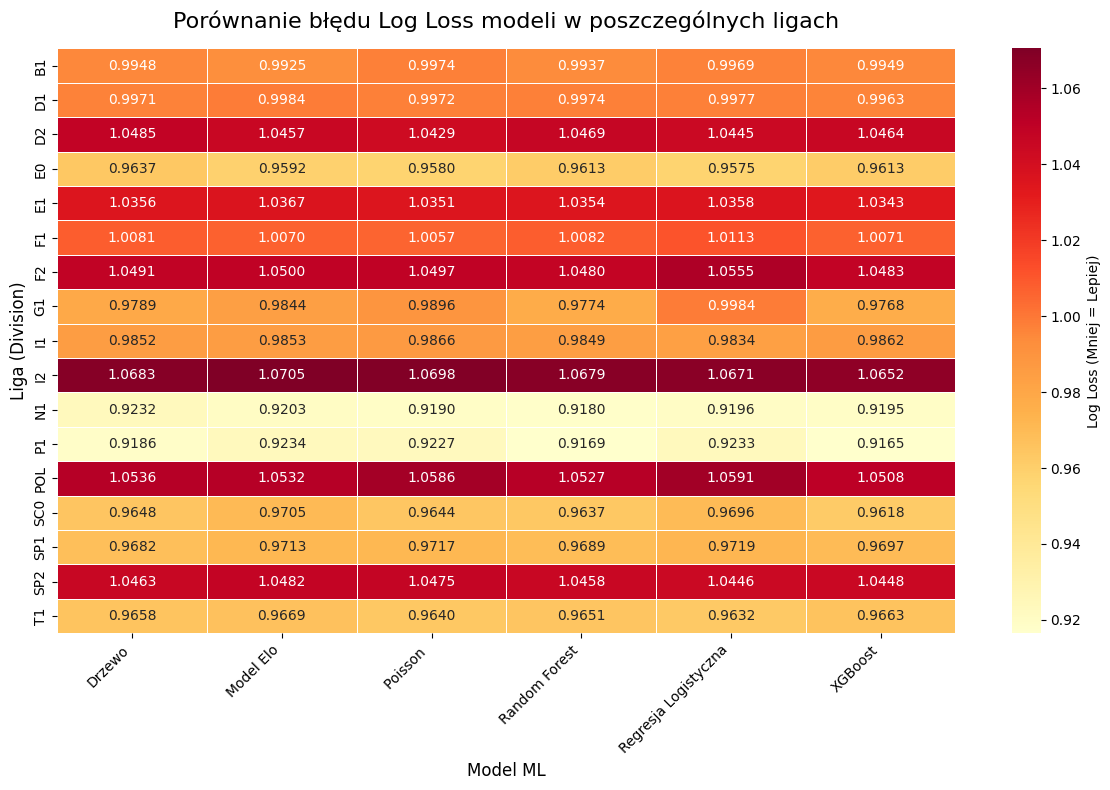

In [81]:
print("\n---  ANALIZA LIGOWA ---")
tabela_ligi = analiza.analiza_predykcji_ligi(modele_slownik=slownik_modeli)

# Jakość Predykcji w czasie


--- URUCHAMIAM ANALIZĘ CZASOWĄ ---
ZBIORCZA JAKOŚĆ PREDYKCJ ROK PO ROKU 
 Rok  Mecze                Model  Accuracy  Log Loss
2023   5126              XGBoost    0.5107    0.9931
2023   5126        Random Forest    0.5111    0.9946
2023   5126             Poisson     0.5137    0.9948
2023   5126 Regresja Logistyczna    0.5144    0.9948
2023   5126               Drzewo    0.5111    0.9954
2023   5126            Model Elo    0.5119    0.9960
2024   5494        Random Forest    0.4964    1.0031
2024   5494              XGBoost    0.4956    1.0032
2024   5494               Drzewo    0.4945    1.0036
2024   5494            Model Elo    0.4956    1.0048
2024   5494             Poisson     0.4942    1.0050
2024   5494 Regresja Logistyczna    0.4956    1.0058
2025   2811        Random Forest    0.5084    1.0069
2025   2811             Poisson     0.5080    1.0075
2025   2811              XGBoost    0.5098    1.0079
2025   2811            Model Elo    0.5098    1.0082
2025   2811 Regresja Logi

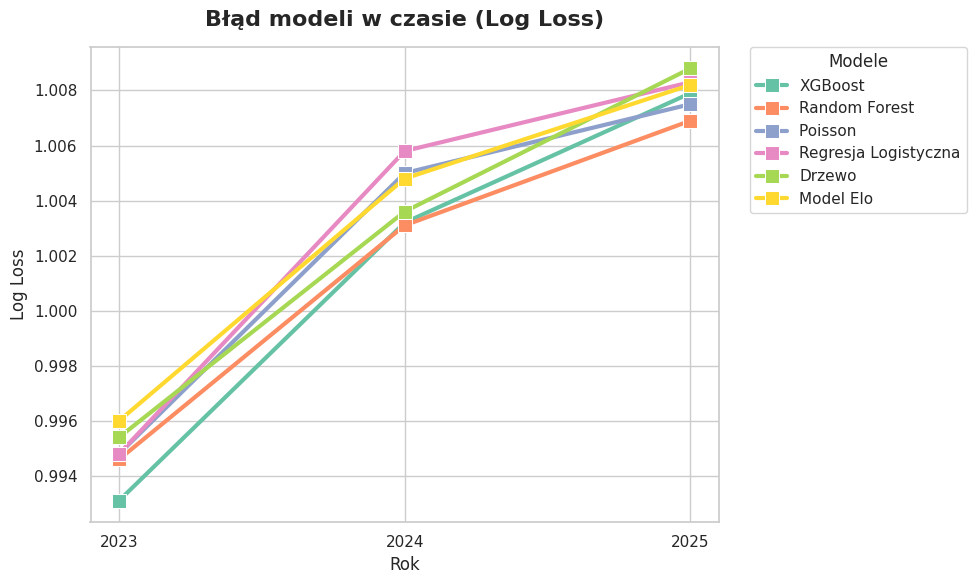

In [82]:
print("\n--- URUCHAMIAM ANALIZĘ CZASOWĄ ---")
tabela_czasowa = analiza.analiza_predykcji_czasowa(modele_slownik=slownik_modeli, kolumna_data='MatchDate')

# Permutation Feature Importance


---PERMUTATION FEATURE IMPORTANCE ---

 Rozpoczynam Permutation Feature Importance dla 4 modeli.
 -> Przetwarzam model: Regresja Logistyczna
 -> Przetwarzam model: Drzewo Decyzyjne
 -> Przetwarzam model: Random Forest
 -> Przetwarzam model: XGBoost


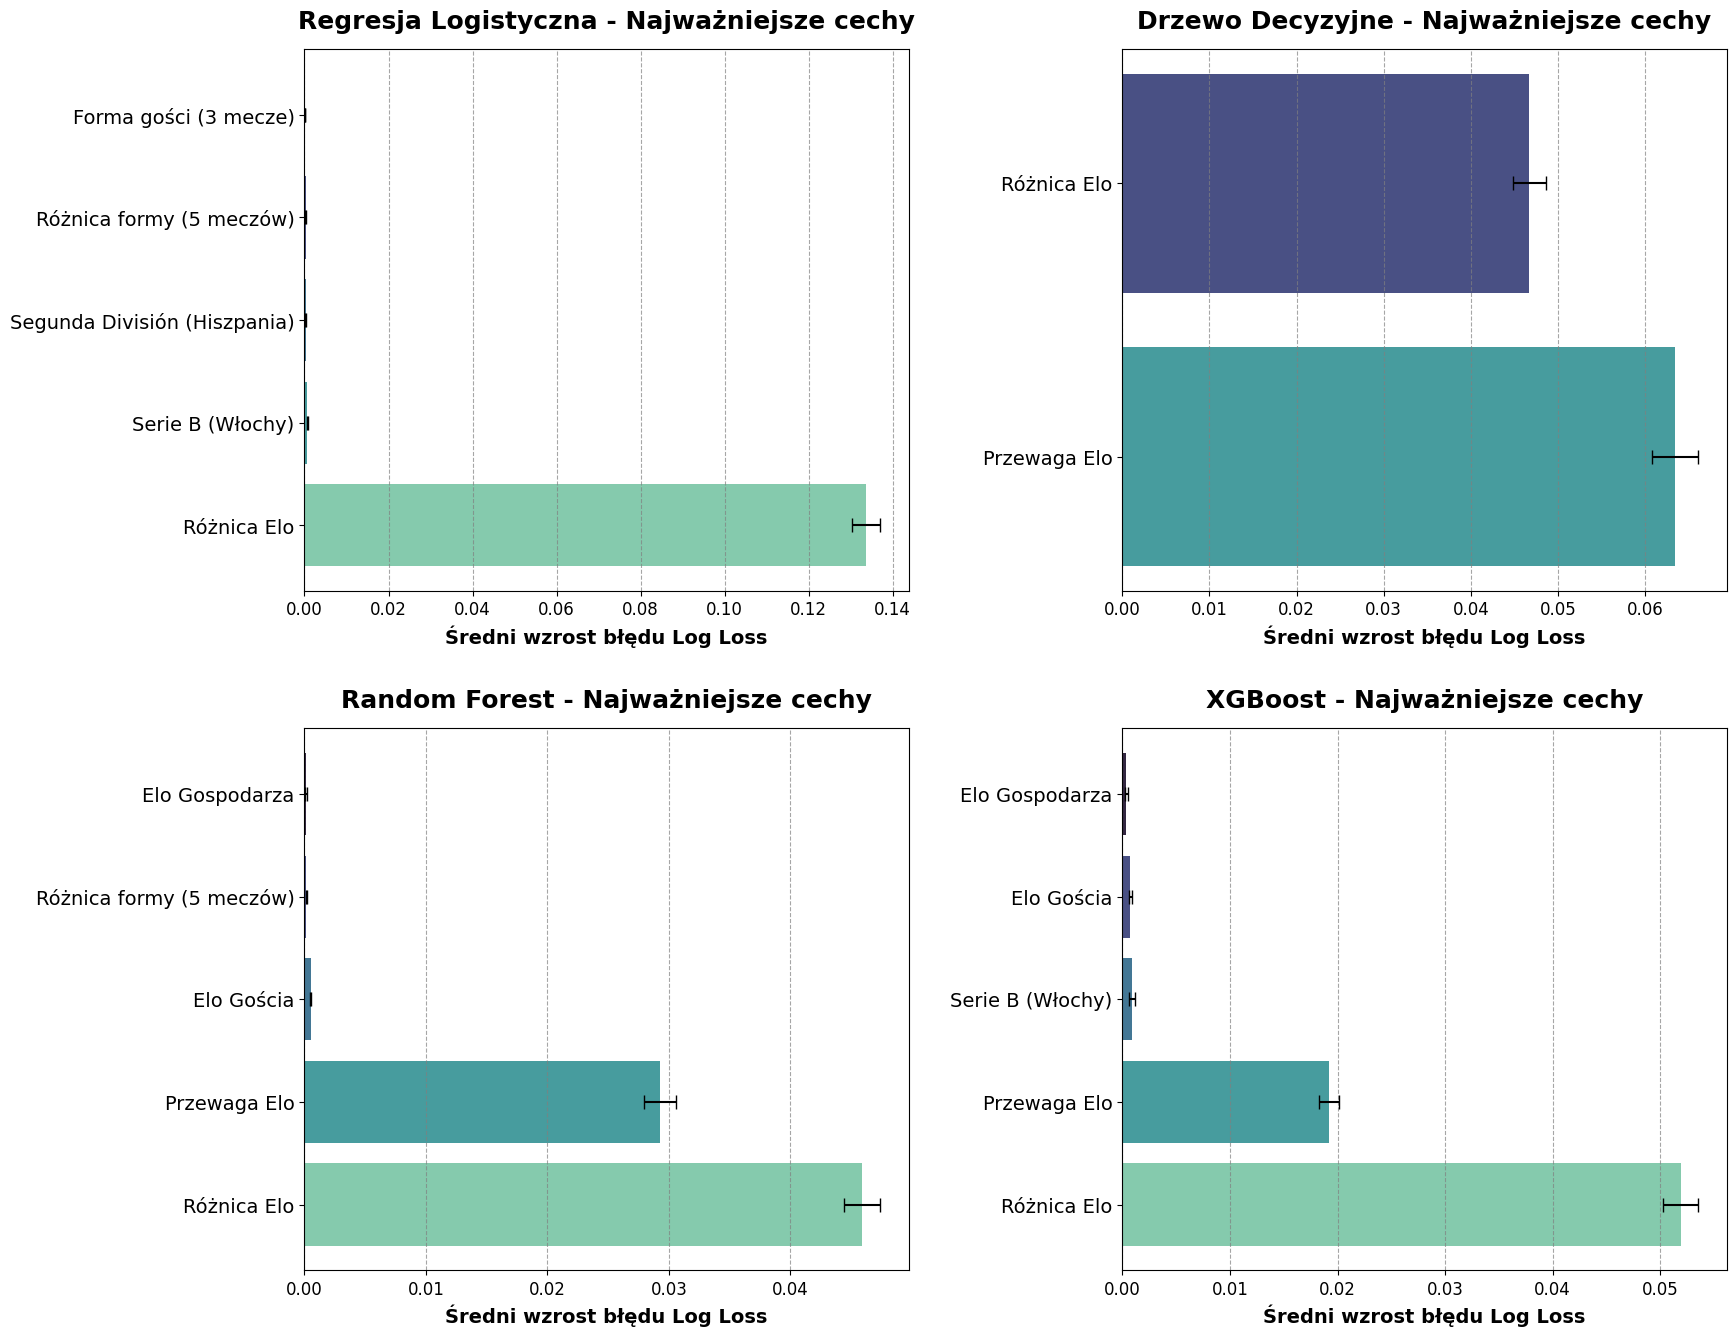

In [83]:
print("\n---PERMUTATION FEATURE IMPORTANCE ---")

slownik_samych_modeli = {
    'Regresja Logistyczna': lr_model,
    'Drzewo Decyzyjne': dt_model,
    'Random Forest': rf_model,
    'XGBoost': xgb_model
}

nazwy_kolumn_po_transformacji = preprocessor.get_feature_names_out()
waznosci_wszystkich_modeli = analiza.analiza_wplywu_cech_zbiorcza(
    slownik_wytrenowanych_modeli=slownik_samych_modeli, 
    X_test_prep=X_test_final_prep, 
    prawdziwe_nazwy_kolumn=nazwy_kolumn_po_transformacji, 
    top_n=5  
)

# Macierze Pomyłek


--- MACIERZE POMYŁEK ---


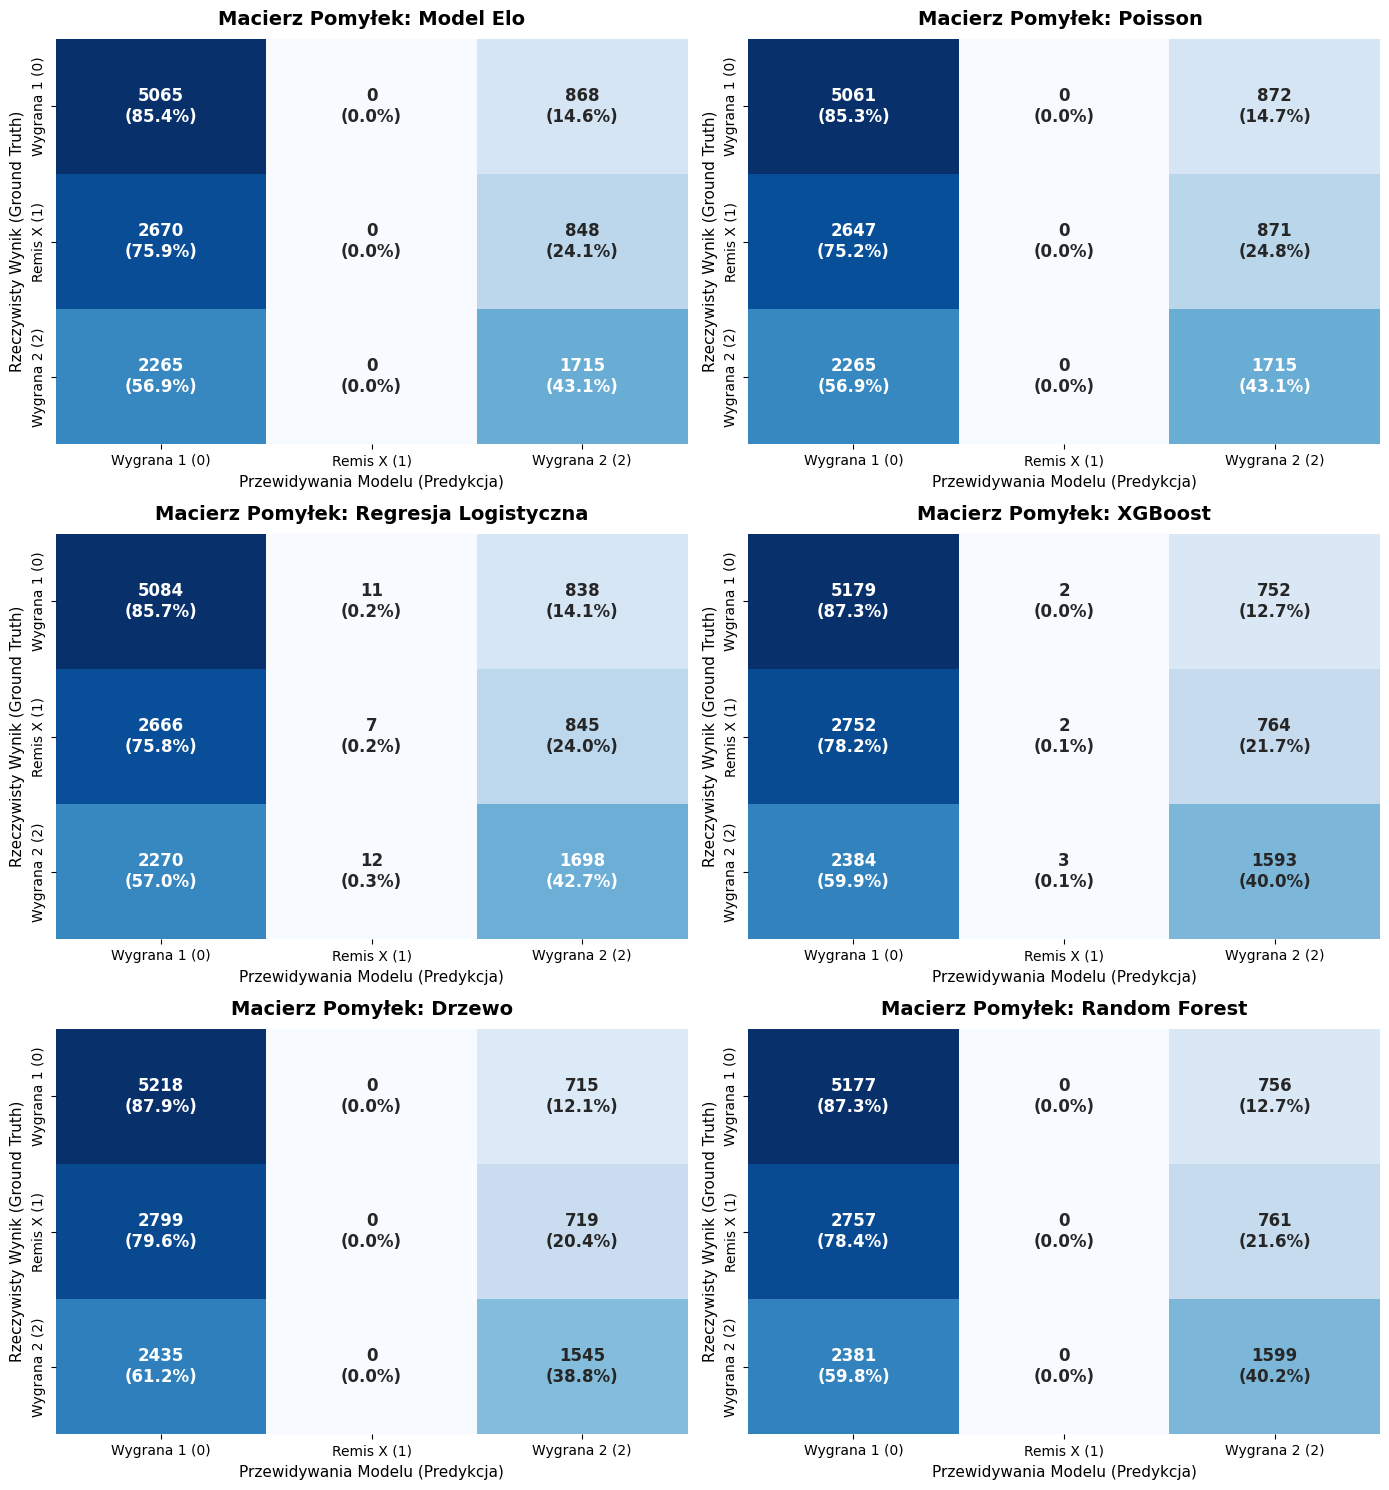

In [84]:
print("\n--- MACIERZE POMYŁEK ---")
analiza.macierze_pomylek(modele_slownik=slownik_modeli)